# CS771 Mini-Project 1

**Solution for parts 1 to 5.

**The task.** At the *issue time* 12:00 IST on day $d$ we forecast PM2.5 at all 468 Bihar stations for 12:00 on day $d+1$ (a 24-hour lead).

**Things to keep in mind**:

| Rule | How this notebook enforces it |
|---|---|
| Features use only readings timestamped ≤ issue time | every feature reads rows `issue_pos - lag` with `lag ≥ 0` (asserted), plus a *future-poisoning test* (§0.5) |
| Split by **target** date: train = targets 1 Jan–31 Aug, validation = 1 Sep–30 Nov | §0.4 builds the split once and asserts it; we cap training targets at 31 Aug **12:00** (= first validation issue time) |
| Scalers, means and every fitted statistic use training rows only | scalers sit inside sklearn pipelines fitted on train rows; the station long-run mean is computed from rows ≤ 31 Aug 12:00 (asserted) |
| All model/feature choices made on validation; validation = every station × every 12:00 target (91 × 468) | asserted in §0.4; nothing is ever dropped from validation |
| No shuffling, fixed seeds | rows are kept in time order; `RANDOM_STATE = 0` everywhere |



## 0. Setup

We keep all reusable code in `src/` so that the notebook stays readable and most importantly so that **the exact same feature code** is used for training here and inside `submission/forecast.py`:

| module | contents |
|---|---|
| `src/config.py` | paths, split dates, seeds, km constants |
| `src/data.py` | loading, km coordinates, nearest neighbours, split helpers |
| `src/features.py` | **all** feature builders |
| `src/metrics.py` | RMSE / MAE overall and per month |
| `src/model.py` | our final model (ridge + ExtraTrees average) |
| `src/idw.py`, `src/plotting.py` | Part 4 interpolation and maps |

In [ ]:
import sys
if "google.colab" in sys.modules:
    !mkdir -p /Task/starter
    !cp -r /content/data /Task/data
    !cp /content/starter/* /Task/starter/

In [ ]:
import sys, time, shutil, subprocess, hashlib, importlib.util
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display

MP1 = Path.cwd()
assert (MP1 / "src").exists(), "run this notebook from the MP1 folder"
sys.path.insert(0, str(MP1))

from src import config as C, data as D, features as F, metrics as M, idw as IDW, plotting as P, model as FM

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge, Lasso, HuberRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.kernel_approximation import RBFSampler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

RANDOM_STATE = C.RANDOM_STATE
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)

C.FIG_DIR.mkdir(exist_ok=True)
RES_DIR = MP1 / "results"
RES_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2})

def savefig(fig, name):
    fig.savefig(C.FIG_DIR / name, dpi=130, bbox_inches="tight")

T0 = time.time()
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.1.3 | pandas 2.2.3


### 0.1 Load the Bihar data and check it

**What:** read the wide hourly table (one row per hour, one column per station) and the station table.
**Why:** before modelling anything we confirm the data is completely fine, IST timestamps with no missing hours, string station IDs in the same order as `bihar_stations.csv`.
**Look for:** all asserts pass; the min/max of the readings.

In [ ]:
W = D.load_bihar()                     # DatetimeIndex 'timestamp' (IST), string columns
stations = D.load_stations()           # index: sensor_id (string)
assert list(stations.index) == list(W.columns), "station order must match the hourly columns"
assert all(isinstance(c, str) for c in W.columns), "station IDs must be strings"

V = W.to_numpy(dtype=float)            # (8040, 468) numpy array used by all feature code
times = W.index
STATION_IDS = W.columns.to_numpy()
S = V.shape[1]

print("shape:", W.shape, "| first:", times.min(), "| last:", times.max())
assert W.shape == (8040, C.N_STATIONS)
assert W.notna().all().all(), "README says there are no missing values"
assert (times.to_series().diff().dropna() == pd.Timedelta("1h")).all(), "hours must be consecutive"
print(f"min reading {V.min():.2f}, max reading {V.max():.2f}, mean {V.mean():.1f} µg/m³")
print("readings exactly at 500 (probable sensor ceiling):", int((V == 500).sum()))
assert np.array_equal(F.clean_history(V), V)     # the forecast-time safety net is a no-op on this data

shape: (8040, 468) | first: 2024-01-01 00:00:00 | last: 2024-11-30 23:00:00
min reading 1.00, max reading 500.00, mean 69.9 µg/m³
readings exactly at 500 (probable sensor ceiling): 49


**Interpretation.** The file is complete (no NaN, no missing hours), values lie between 1 and 500 µg/m³ (mean ≈ 70), and 49 readings sit exactly at 500, which is probably the sensor's upper limit (a real value above 500 would be recorded as 500). The dataset we are using is not completely raw. Before the data was given to us, the missing values (gaps) were already filled by guessing the pollution levels based on nearby stations. The problem is that these filled values weren't marked or flagged. Because our model cannot tell the difference between real sensor measurements and these guessed values, its predicting power will naturally be limited. We must mention this flaw in our final project report.

### 0.2 Geometry: km coordinates and the 10 nearest neighbours

**What:** convert latitude/longitude to approximate km with the formula given  with the problem statement.
$x = (\text{lon} - 85.5)\times 100.3,\; y = (\text{lat} - 25.7)\times 110.6$, then find each station's 10 nearest *other* stations.
**Why:** a degree of longitude is shorter than a degree of latitude at 25.7°N, so Euclidean distance on raw degrees would distort neighbourhoods. Converting to km first makes "nearest" mean nearest on the ground.
**Look for:** no station is its own neighbour; typical neighbour distances.

In [ ]:
xy = D.to_km(stations["longitude"], stations["latitude"])     # (468, 2) km
nbr_idx = D.neighbour_index(xy, k=C.N_NEIGHBOURS)             # (468, 10) indices of nearest OTHER stations
Dkm = D.distance_matrix_km(xy)
nbr_dist = np.take_along_axis(Dkm, nbr_idx, axis=1)

assert not (nbr_idx == np.arange(S)[:, None]).any(), "a station must not be its own neighbour"
print("distance to nearest other station (km): median %.1f, max %.1f" % (np.median(nbr_dist[:, 0]), nbr_dist[:, 0].max()))
print("distance to 10th nearest (km):           median %.1f, max %.1f" % (np.median(nbr_dist[:, -1]), nbr_dist[:, -1].max()))

distance to nearest other station (km): median 9.0, max 34.3
distance to 10th nearest (km):           median 24.9, max 71.7


### 0.3 The time split (by **target** date)

**What:** list every 12:00 target in the training window (1 Jan–31 Aug) and in validation (1 Sep–30 Nov). The issue time of each forecast is target = 24 h.
**Why :** a forecast is used on *future* days, so validation must be *later* than training. A random split would let the model learn from days that come after the ones it is tested on, which is cheating (and gives optimistic numbers).

Details we must get right:
* The first training issue time with a full 24 h of history is **2 Jan 12:00** (1 Jan 12:00 would need readings from 31 Dec).
* The last training target is **31 Aug 12:00**, which equals the first validation issue time, so every training target is already known when the first validation forecast is issued.
* Validation issue times are 31 Aug 12:00 … 29 Nov 12:00: **91 days × 468 stations = 42,588 forecasts**.

In [ ]:
train_targets = D.noon_targets(C.TRAIN_TARGET_START, C.TRAIN_TARGET_END)
val_targets = D.noon_targets(C.VAL_TARGET_START, C.VAL_TARGET_END)

# Part 1 rows: need 24 h of history
tr_pos, tr_tg = D.split_issue_positions(times, train_targets, lead=24, min_history=24)
va_pos, va_tg = D.split_issue_positions(times, val_targets, lead=24, min_history=24)

print(f"train: {len(tr_pos)} issue days, {times[tr_pos[0]]} ... {times[tr_pos[-1]]}  -> {len(tr_pos) * S:,} rows")
print(f"valid: {len(va_pos)} issue days, {times[va_pos[0]]} ... {times[va_pos[-1]]}  -> {len(va_pos) * S:,} rows")

# ---- leakage / protocol asserts -------------------------------------------------------------
assert tr_tg.max() <= C.TRAIN_TARGET_END                         # train targets <= 31 Aug 12:00
assert (times[tr_pos] + pd.Timedelta(hours=24) == tr_tg).all()   # target = issue + 24 h
assert tr_tg.max() <= times[va_pos].min()                         # all train targets known at first val issue
assert len(va_pos) == C.N_VAL_DAYS and va_tg.min() == C.VAL_TARGET_START and va_tg.max() == C.VAL_TARGET_END
assert (np.diff(tr_pos) > 0).all() and (np.diff(va_pos) > 0).all()  # chronological, never shuffled

y_va = F.targets(V, va_pos)                     # (42588,) observed PM2.5 at the validation targets
t_va = np.repeat(va_tg, S)                      # target time of every validation row
assert len(y_va) == C.N_VAL_DAYS * C.N_STATIONS == 42588
# row order is issue-major then station: check one entry against a direct pandas lookup
assert y_va[5 * S + 7] == W.loc[va_tg[5], STATION_IDS[7]]

train: 242 issue days, 2024-01-02 12:00:00 ... 2024-08-30 12:00:00  -> 113,256 rows
valid: 91 issue days, 2024-08-31 12:00:00 ... 2024-11-29 12:00:00  -> 42,588 rows


### 0.4 A leakage test we can run on any feature builder: "future poisoning"

**What:** for some issue times $p$, we replace *every reading after $p$* by an absurd value (10⁶) and rebuild the features. If any feature secretly used the future, it would change.
**Why:** asserts on index arithmetic are good, but this test checks the actual behaviour of the code ,  it is the most direct proof that features are computable at the issue time.

In [ ]:
def future_poisoning_test(builder, positions):
    # builder(V, positions) -> feature matrix.  Features must not change when the future is destroyed.
    for p in positions:
        V_poisoned = V.copy()
        V_poisoned[p + 1:] = 1e6                       # destroy everything after the issue time
        a = builder(V, np.array([p]))
        b = builder(V_poisoned, np.array([p]))
        assert np.array_equal(a, b), f"feature builder looks into the future at row {p}"
    return True

check_pos = [tr_pos[0], tr_pos[100], va_pos[0], va_pos[-1]]
print("baseline features pass:", future_poisoning_test(lambda VV, pp: F.baseline_features(VV, times, pp, nbr_idx), check_pos))

baseline features pass: True


---
# Part 1: The two required baselines

## 1.1 Persistence

**What:** forecast for 12:00 tomorrow = this station's reading at 12:00 today.
**Why:** it is the simplest honest forecast. Any model worth using must beat it. PM2.5 changes slowly from day to day, so persistence is surprisingly strong.

We compute it **two independent ways** : (a) as the `lag_0h` column of the feature matrix and (b) by direct pandas lookup of `W` at target − 24 h  and assert they agree exactly. This checks our index bookkeeping.

In [ ]:
X1_tr = F.baseline_features(V, times, tr_pos, nbr_idx)     # (113256, 29)
X1_va = F.baseline_features(V, times, va_pos, nbr_idx)     # (42588, 29)
y1_tr = F.targets(V, tr_pos)
print("train X:", X1_tr.shape, "| validation X:", X1_va.shape)

pers_va = X1_va[:, F.BASELINE_FEATURE_NAMES.index("lag_0h")]                   # way (a)
pers_va_direct = W.loc[va_tg - pd.Timedelta(hours=24)].to_numpy().reshape(-1)    # way (b)
assert np.array_equal(pers_va, pers_va_direct), "two persistence computations disagree"
print("persistence computed two ways: identical")

train X: (113256, 29) | validation X: (42588, 29)
persistence computed two ways: identical


## 1.2 The fixed ridge baseline (29 features)

**What:** per station and issue time $t$ = day $d$, 12:00:
* the station's 24 hourly readings $t, t-1\text{h}, \dots, t-23\text{h}$ (24),
* the mean of its 10 nearest other stations at $t$ (1) and over $t-23\text{h}\dots t$ (1),
* the network mean of all 468 stations at $t$ (1),
* $\sin(2\pi d/365)$, $\cos(2\pi d/365)$ with $d$ = days since 1 Jan 2024 **of the issue day** (2).

Fit `Ridge(alpha=1.0)` on **raw, unscaled** features, pooling all stations and all training targets with 24 h of history; clip negative forecasts to 0.



In [ ]:
ridge_base = Ridge(alpha=1.0).fit(X1_tr, y1_tr)            # exactly as specified: raw features, alpha = 1
ridge_va = np.clip(ridge_base.predict(X1_va), 0, None)
ridge_tr = np.clip(ridge_base.predict(X1_tr), 0, None)
print("negative validation predictions clipped:", int((ridge_base.predict(X1_va) < 0).sum()))

part1 = M.results_table({"Persistence": pers_va, "Ridge baseline": ridge_va}, y_va, t_va)
display(part1)
part1.to_csv(RES_DIR / "part1_baselines.csv")
print(f"(ridge train RMSE {M.rmse(ridge_tr, y1_tr):.2f}, close to validation, so ridge is not overfitting)")

negative validation predictions clipped: 0


overall           Sep           Oct           Nov       
                  RMSE    MAE   RMSE    MAE   RMSE    MAE   RMSE    MAE
Persistence      32.75  17.47  23.33   8.91  20.22  11.97  47.81  31.70
Ridge baseline   29.58  18.16  20.34  10.35  19.36  13.46  43.06  30.81

(ridge train RMSE 28.00, close to validation, so ridge is not overfitting)


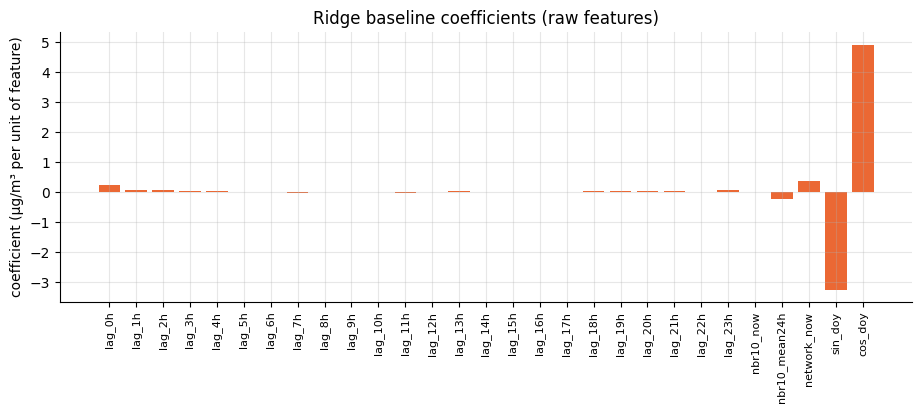

lag_0h           0.229
lag_1h           0.086
lag_2h           0.060
lag_3h           0.030
lag_4h           0.032
lag_5h           0.009
lag_6h           0.017
lag_7h          -0.033
lag_8h           0.011
lag_9h           0.002
lag_10h          0.007
lag_11h         -0.022
lag_12h          0.015
lag_13h          0.033
lag_14h          0.022
lag_15h          0.004
lag_16h          0.002
lag_17h          0.012
lag_18h          0.042
lag_19h          0.039
lag_20h          0.024
lag_21h          0.027
lag_22h          0.021
lag_23h          0.056
nbr10_now        0.008
nbr10_mean24h   -0.213
network_now      0.358
sin_doy         -3.240
cos_doy          4.915


In [ ]:
coef = pd.Series(ridge_base.coef_, index=F.BASELINE_FEATURE_NAMES)
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(range(len(coef)), coef.values, color=P.METHOD_COLORS["Ridge baseline"])
ax.set_xticks(range(len(coef))); ax.set_xticklabels(coef.index, rotation=90, fontsize=8)
ax.set_ylabel("coefficient (µg/m³ per unit of feature)")
ax.set_title("Ridge baseline coefficients (raw features)")
savefig(fig, "part1_ridge_coefficients.png"); plt.show()
print(coef.round(3).to_string())

**Interpretation.**
* **RMSE:** ridge (29.58) beats persistence (32.75) overall and in every month.
* **MAE:** persistence wins (17.47 vs 18.16), and wins clearly in the clean months (Sep: 8.91 vs 10.35; Oct: 11.97 vs 13.46). Ridge only wins MAE in November.
* So **neither baseline wins on both metrics.**
* November dominates both metrics: levels rise from ≈ 40 to ≈ 175 µg/m³ during the month, and day-to-day jumps are large.

The coefficients show what ridge learned. It keeps only ≈ 0.23 of the current reading plus smaller weights on the other lags and the network mean (0.36), so it **shrinks toward a typical level** instead of copying today. The sin/cos seasonal terms carry large weights fitted on Jan–Aug only, and they shift the validation forecasts (ridge's mean bias is ≈ +5 µg/m³ in validation, see Part 3).

## 1.3 Question: RMSE vs MAE: why can a squared-error model lose on absolute error?

**As we know:** minimising squared error = maximum likelihood under **Gaussian** noise, and the best constant prediction under squared loss is the **conditional mean**. Minimising absolute error = maximum likelihood under **Laplace** noise, and its best prediction is the **conditional median**. PM2.5 changes are skewed with heavy tails (sudden smog episodes), so mean ≠ median and the two losses reward different forecasts.

Below we look at the whole distribution of absolute errors, not just the two summary numbers.

rows where ridge is closer than persistence: 43.0%
median |error|:   persistence  8.78   ridge 11.34
90th pct |error|: persistence 41.25   ridge 40.23
99th pct |error|: persistence 136.84   ridge 115.88
day-to-day change (target - issue reading): mean 0.47, median 0.75, skewness -0.51


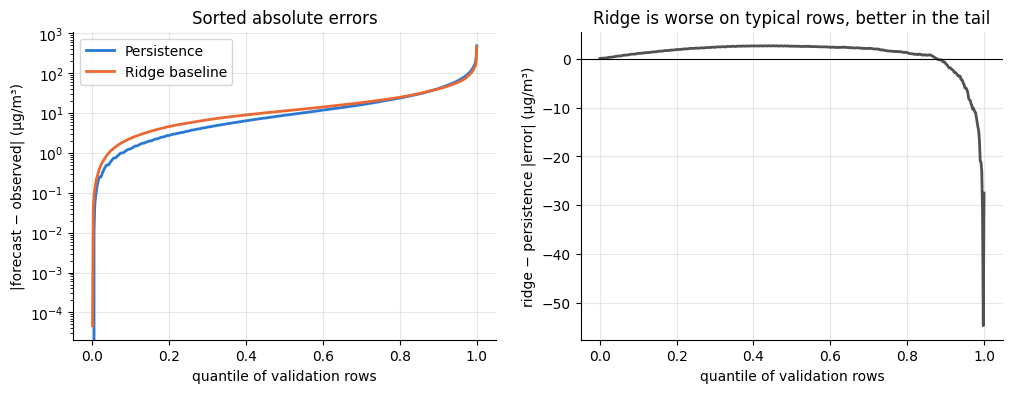

In [ ]:
abs_p, abs_r = np.abs(pers_va - y_va), np.abs(ridge_va - y_va)
print(f"rows where ridge is closer than persistence: {np.mean(abs_r < abs_p):.1%}")
print(f"median |error|:   persistence {np.median(abs_p):5.2f}   ridge {np.median(abs_r):5.2f}")
print(f"90th pct |error|: persistence {np.quantile(abs_p, .9):5.2f}   ridge {np.quantile(abs_r, .9):5.2f}")
print(f"99th pct |error|: persistence {np.quantile(abs_p, .99):5.2f}   ridge {np.quantile(abs_r, .99):5.2f}")
chg = y_va - pers_va
print(f"day-to-day change (target - issue reading): mean {chg.mean():.2f}, median {np.median(chg):.2f}, skewness {pd.Series(chg).skew():.2f}")

q = np.linspace(0, 1, 501)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(q, np.quantile(abs_p, q), color=P.METHOD_COLORS["Persistence"], label="Persistence")
axes[0].plot(q, np.quantile(abs_r, q), color=P.METHOD_COLORS["Ridge baseline"], label="Ridge baseline")
axes[0].set_yscale("log"); axes[0].set_xlabel("quantile of validation rows"); axes[0].set_ylabel("|forecast − observed| (µg/m³)")
axes[0].set_title("Sorted absolute errors"); axes[0].legend()
diff = np.quantile(abs_r, q) - np.quantile(abs_p, q)
axes[1].plot(q, diff, color="#52514e"); axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_xlabel("quantile of validation rows"); axes[1].set_ylabel("ridge − persistence |error| (µg/m³)")
axes[1].set_title("Ridge is worse on typical rows, better in the tail")
savefig(fig, "part1_rmse_vs_mae.png"); plt.show()

**Answer: does one baseline win on both metrics?** No. Ridge wins RMSE (29.58 vs 32.75) but persistence wins MAE (17.47 vs 18.16).

**Why can a model trained on squared error lose on absolute error?**
1. **Squared loss targets the mean; absolute loss rewards the median** (Gaussian vs Laplace likelihood). Squared loss punishes a 100 µg/m³ miss 100× more than a 10 µg/m³ miss, so ridge hedges: it pulls forecasts toward the average to limit the rare huge errors.
2. The plot shows the price. Ridge is closer than persistence on only **43 % of rows**, and its median absolute error is larger (11.3 vs 8.8). It wins in the **tail**: the 99th-percentile error is 116 vs 137.
3. RMSE is dominated by that tail (big November jumps), so ridge wins RMSE. MAE weights every row equally and most rows are ordinary days where "no change" is nearly right, so persistence wins MAE.
4. On top of this, ridge carries a seasonal **bias** (+5 µg/m³ on average in validation, from its sin/cos terms fitted on Jan–Aug). A constant bias adds directly to MAE on the many calm days (September MAE 10.4 vs 8.9).

---
# Part 2 : Improving the forecast

## 2.1 The fitted context (training rows only)

Some features need statistics *fitted* on data: the station's long-run mean and standard deviation. **Leakage rule:** these are computed only from readings up to the last training target, 31 Aug 12:00. We assert this by recomputing them with pandas.

We also precompute, for radii 10 / 25 / 50 km, an averaging matrix over the *other* stations inside the radius (a station with nobody inside a radius falls back to its 10 nearest neighbours). Those use only coordinates, not readings.

In [ ]:
train_end_pos = times.get_loc(C.TRAIN_TARGET_END)
ctx = F.make_context(xy, nbr_idx, V[: train_end_pos + 1])             # readings <= 31 Aug 12:00 only

assert np.allclose(ctx["station_mean"], W.loc[: C.TRAIN_TARGET_END].mean().to_numpy())
assert times[train_end_pos] == C.TRAIN_TARGET_END
for r in ctx["radii_km"]:
    n_in = ((Dkm <= r) & ~np.eye(S, dtype=bool)).sum(axis=1)
    print(f"radius {r:4.0f} km: median {np.median(n_in):4.0f} other stations inside, {np.sum(n_in == 0)} stations with none (fallback to 10-NN)")

radius   10 km: median    1 other stations inside, 166 stations with none (fallback to 10-NN)
radius   25 km: median   10 other stations inside, 2 stations with none (fallback to 10-NN)
radius   50 km: median   38 other stations inside, 0 stations with none (fallback to 10-NN)


## 2.2 Feature groups

We organise the features into **8 groups** (63 features), each built from one idea (the PDF's ablation unit). All are computed relative to the issue time and use only rows ≤ issue time.

| group | # | idea | related concept |
|---|---|---|---|
| `recent24` | 24 | the station's last 24 hourly readings (same as Part 1) | linear features |
| `daily_hist` | 6 | the station's daily mean 2…7 days back (longer memory) | |
| `same_hour` | 7 | the station's reading at the *target* hour (12:00) on each of the 7 previous days | captures the daily cycle |
| `trend` | 6 | today − yesterday mean, change over 3 h, 24 h slope, 24 h std/min/max | nonlinear summaries (feature maps) |
| `neighbourhood` | 8 | mean of 10 nearest neighbours and of stations within 10/25/50 km, now and over 24 h | neighbourhoods, km distances |
| `network` | 4 | network mean now, over 24 h, over 7 days, and its day-on-day change | overall pollution level |
| `station` | 4 | station's training-period mean and std, x/y position (km) | prototype per station |
| `calendar` | 4 | sin/cos of target day-of-year, sin/cos of target day-of-week | cyclic encoding |

The rich features need 7 days (168 h) of history, so the first usable training issue day is 8 Jan: **236 issue days × 468 = 110,448 training rows** (vs 113,256 for Part 1). Validation is unchanged (all 91 days).

In [ ]:
tr2_pos, tr2_tg = D.split_issue_positions(times, train_targets, lead=24, min_history=F.HISTORY_HOURS)
X2_tr, feat_names, group_slices = F.rich_features(V, times, tr2_pos, ctx)
X2_va, _, _ = F.rich_features(V, times, va_pos, ctx)
y2_tr = F.targets(V, tr2_pos)
pers2_tr = X2_tr[:, feat_names.index("lag_0h")]
assert np.array_equal(X2_va[:, feat_names.index("lag_0h")], pers_va)
assert tr2_tg.max() <= C.TRAIN_TARGET_END
print("train:", X2_tr.shape, "| validation:", X2_va.shape, "| first train issue:", times[tr2_pos[0]])
print("rich features pass the future-poisoning test:",
      future_poisoning_test(lambda VV, pp: F.rich_features(VV, times, pp, ctx)[0], [tr2_pos[0], va_pos[0], va_pos[-1]]))

group_table = pd.DataFrame({"group": list(group_slices),
                            "n_features": [s.stop - s.start for s in group_slices.values()],
                            "features": [", ".join(feat_names[s][:4]) + (" ..." if s.stop - s.start > 4 else "") for s in group_slices.values()]})
display(group_table)
print("total features:", X2_tr.shape[1])

def cols(groups):
    # column indices of a list of groups
    return np.concatenate([np.arange(group_slices[g].start, group_slices[g].stop) for g in groups])

train: (110448, 63) | validation: (42588, 63) | first train issue: 2024-01-08 12:00:00
rich features pass the future-poisoning test: True


,group,n_features,features
0,recent24,24,"lag_0h, lag_1h, lag_2h, lag_3h ..."
1,daily_hist,6,"daymean_2d_ago, daymean_3d_ago, daymean_4d_ago..."
2,same_hour,7,"targethour_1d_ago, targethour_2d_ago, targetho..."
3,trend,6,"today_minus_yday, change_3h, slope_24h, std_24..."
4,neighbourhood,8,"nbr10_now, nbr10_mean24h, r10km_now, r10km_mea..."
5,network,4,"net_now, net_mean24h, net_mean7d, net_today_mi..."
6,station,4,"station_train_mean, station_train_std, x_km, y_km"
7,calendar,4,"sin_doy, cos_doy, sin_dow, cos_dow"


total features: 63


## 2.3 Experiment log

**What:** try the feature ideas and several allowed models; record *every* attempt with its validation RMSE and MAE (and train RMSE, to watch for overfitting).
**Protocol:** fit on training rows (targets ≤ 31 Aug 12:00) → score on the full validation set. Choices are made on validation only; the December test set is never seen.

A trick we use for most models: predict the **change** $y - x_{\text{now}}$ (target minus the reading at the issue time) and add persistence back. For a linear model this is almost the same problem, but tree models cannot extrapolate beyond the target values seen in training, and predicting a *change* lets them follow levels (like November's) that are higher than most training days.

In [ ]:
LOG = []

def log_exp(name, model, features, p_val, p_train=None, n_train=None, note=""):
    p_val = np.clip(p_val, 0, None)
    row = {"experiment": name, "model": model, "features": features,
           "n_train_rows": n_train, "train_RMSE": None if p_train is None else round(M.rmse(np.clip(p_train, 0, None), y_true_train[n_train]), 2),
           "val_RMSE": round(M.rmse(p_val, y_va), 2), "val_MAE": round(M.mae(p_val, y_va), 2), "note": note}
    LOG.append(row)
    print(f"{name:42s} val RMSE {row['val_RMSE']:6.2f}  MAE {row['val_MAE']:6.2f}" + ("" if p_train is None else f"   train RMSE {row['train_RMSE']:6.2f}"))
    return p_val

y_true_train = {len(y1_tr): y1_tr, len(y2_tr): y2_tr}     # lookup of the right training targets by size
N1, N2 = len(y1_tr), len(y2_tr)
ALL = list(F.ALL_GROUPS)

_ = log_exp("E0 persistence", "persistence", "reading at issue time", pers_va)
_ = log_exp("E1 ridge baseline (Part 1)", "Ridge a=1, raw", "29 baseline", ridge_va, ridge_tr, N1)

# E2: the baseline features, but scaled (scaler fitted on TRAIN only inside the pipeline)
m = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(X1_tr, y1_tr)
_ = log_exp("E2 ridge baseline feats, scaled", "Scaler+Ridge a=1", "29 baseline", m.predict(X1_va), m.predict(X1_tr), N1)

# E3: all rich features, plain target
m = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(X2_tr, y2_tr)
_ = log_exp("E3 ridge rich feats", "Scaler+Ridge a=1", "8 groups (63)", m.predict(X2_va), m.predict(X2_tr), N2)

E0 persistence                             val RMSE  32.75  MAE  17.47
E1 ridge baseline (Part 1)                 val RMSE  29.58  MAE  18.16   train RMSE  28.00
E2 ridge baseline feats, scaled            val RMSE  29.58  MAE  18.16   train RMSE  28.00
E3 ridge rich feats                        val RMSE  29.41  MAE  17.88   train RMSE  26.29


### Ridge regularisation path

**What:** sweep $\alpha$ for scaled ridge on all rich features (residual target), plotting train and validation RMSE.
**Why:** $\alpha$ trades fitting the training data against keeping weights small. Too small → the model chases noise (variance); too large → it shrinks everything toward the mean (bias).
**Look for:** a shallow minimum. With 110k rows and 63 features ridge is not data-starved, so we expect $\alpha$ to matter only a little.

,train_RMSE,val_RMSE,val_MAE
alpha,,,
1,26.293,29.406,17.875
10,26.294,29.404,17.872
100,26.295,29.386,17.846
300,26.303,29.356,17.798
1000,26.356,29.309,17.702
3000,26.527,29.303,17.594
10000,26.973,29.383,17.412
30000,27.678,29.547,17.057
100000,28.859,30.187,16.735


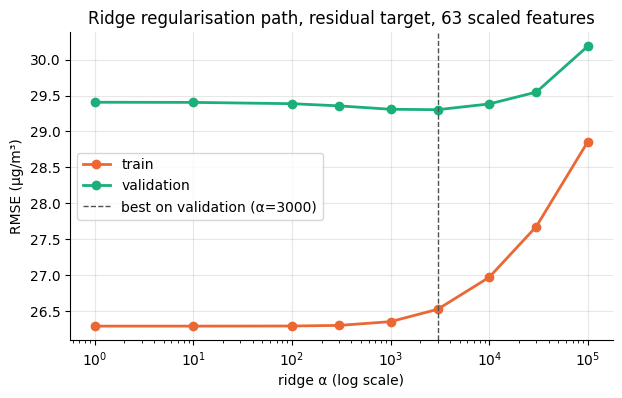

E4 ridge rich, residual, a=3000            val RMSE  29.30  MAE  17.59   train RMSE  26.53


In [ ]:
alphas = [1, 10, 100, 300, 1000, 3000, 10000, 30000, 100000]
path = []
for a in alphas:
    m = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(X2_tr, y2_tr - pers2_tr)
    p_v = np.clip(m.predict(X2_va) + pers_va, 0, None); p_t = np.clip(m.predict(X2_tr) + pers2_tr, 0, None)
    path.append((a, M.rmse(p_t, y2_tr), M.rmse(p_v, y_va), M.mae(p_v, y_va)))
path = pd.DataFrame(path, columns=["alpha", "train_RMSE", "val_RMSE", "val_MAE"]).set_index("alpha")
display(path.round(3))
best_ridge_alpha = path["val_RMSE"].idxmin()

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogx(path.index, path.train_RMSE, "o-", color=P.METHOD_COLORS["Ridge baseline"], label="train")
ax.semilogx(path.index, path.val_RMSE, "o-", color=P.METHOD_COLORS["Our model"], label="validation")
ax.axvline(best_ridge_alpha, color="#52514e", ls="--", lw=1, label=f"best on validation (α={best_ridge_alpha:g})")
ax.set_xlabel("ridge α (log scale)"); ax.set_ylabel("RMSE (µg/m³)"); ax.set_title("Ridge regularisation path, residual target, 63 scaled features")
ax.legend(); savefig(fig, "part2_ridge_alpha_path.png"); plt.show()

m = make_pipeline(StandardScaler(), Ridge(alpha=best_ridge_alpha)).fit(X2_tr, y2_tr - pers2_tr)
p_ridge_rich = log_exp(f"E4 ridge rich, residual, a={best_ridge_alpha:g}", f"Scaler+Ridge a={best_ridge_alpha:g}", "8 groups (63)",
                       m.predict(X2_va) + pers_va, m.predict(X2_tr) + pers2_tr, N2, "alpha from the path")

**Interpretation.**
* **The curve is very flat.** Validation RMSE varies only between 29.30 and 29.41 for α from 1 to 10,000. Training RMSE rises slowly with α.
* **Best alone:** α ≈ 3000 (29.30). Beyond about 10⁴ the penalty starts to underfit (30.19 at 10⁵).
* **The size of the gain:** the rich features beat the 29-feature baseline by only ≈ 0.3 µg/m³. A linear model on PM2.5 history is close to its limit.
* **MAE behaves differently:** it keeps improving up to very large α (16.7 at 10⁵) while RMSE gets worse. Strong shrinkage pulls forecasts toward persistence plus a small change, which suits the typical day (MAE) but not the big jumps (RMSE).

### Other linear variants: Lasso ($\ell_1$), Huber loss, log transform

* **Lasso** ($\ell_1$ penalty) can set weights exactly to zero, i.e. it selects features.
* **Huber loss** is quadratic for small residuals and linear for large ones: it is less pulled by extreme smog days (a compromise between the Gaussian and Laplace likelihoods).
* **Log transform:** model $\log(1+y)$ from $\log(1+x)$ : a multiplicative model where errors scale with the pollution level. Back-transforming the mean of a log gives a *geometric* mean, which is biased low, so we apply the standard "smearing" correction $\hat y = e^{\hat z}\cdot\overline{e^{r}} - 1$.

In [ ]:
sc = StandardScaler().fit(X2_tr)                        # fitted on TRAIN rows only
Z_tr, Z_va = sc.transform(X2_tr), sc.transform(X2_va)

m = Lasso(alpha=0.1, max_iter=5000).fit(Z_tr, y2_tr - pers2_tr)
_ = log_exp("E5 lasso, residual", "Lasso a=0.1", "8 groups (63)", m.predict(Z_va) + pers_va, m.predict(Z_tr) + pers2_tr, N2,
        f"{np.sum(m.coef_ == 0)} of {len(m.coef_)} weights set to 0")

m = HuberRegressor(epsilon=1.35, alpha=1.0, max_iter=500).fit(Z_tr, y2_tr - pers2_tr)
_ = log_exp("E6 Huber loss, residual", "HuberRegressor eps=1.35", "8 groups (63)", m.predict(Z_va) + pers_va, m.predict(Z_tr) + pers2_tr, N2)

pos_cols = X2_tr.min(axis=0) >= 0                       # log only the non-negative features
L_tr, L_va = X2_tr.copy(), X2_va.copy()
L_tr[:, pos_cols], L_va[:, pos_cols] = np.log1p(X2_tr[:, pos_cols]), np.log1p(X2_va[:, pos_cols])
m = make_pipeline(StandardScaler(), Ridge(alpha=100)).fit(L_tr, np.log1p(y2_tr))
smear = np.mean(np.exp(np.log1p(y2_tr) - m.predict(L_tr)))
_ = log_exp("E7 log-log ridge (smearing)", "Scaler+Ridge on log1p", "8 groups (63), logged", np.exp(m.predict(L_va)) * smear - 1,
        np.exp(m.predict(L_tr)) * smear - 1, N2)

E5 lasso, residual                         val RMSE  29.27  MAE  17.58   train RMSE  26.39
E6 Huber loss, residual                    val RMSE  29.66  MAE  16.64   train RMSE  26.75
E7 log-log ridge (smearing)                val RMSE  30.13  MAE  16.69   train RMSE  26.87


### Nonlinear models: KNN, kernels via random features, trees and ensembles

* **KNN regression** predicts the (distance-weighted) average change of the $k$ most similar training rows in scaled feature space.
* **RBF random features** (`RBFSampler`) approximate an RBF-kernel machine with an explicit 500-dimensional feature map followed by ridge : a kernel method that scales to 110k rows.
* **Gradient boosting** (`HistGradientBoostingRegressor`), **random forest** and **extra trees** are flexible tree ensembles. We record train RMSE to see overfitting.

In [ ]:
for k in [50, 200]:
    m = KNeighborsRegressor(n_neighbors=k, weights="distance", n_jobs=-1).fit(Z_tr, y2_tr - pers2_tr)
    log_exp(f"E8 KNN k={k}, distance-weighted", f"KNN k={k}", "8 groups (63), scaled", m.predict(Z_va) + pers_va, None, N2)

m = make_pipeline(StandardScaler(), RBFSampler(gamma=0.005, n_components=500, random_state=RANDOM_STATE), Ridge(alpha=10)).fit(X2_tr, y2_tr - pers2_tr)
_ = log_exp("E9 RBF random features + ridge", "RBFSampler(500, g=0.005)+Ridge", "8 groups (63)", m.predict(X2_va) + pers_va, m.predict(X2_tr) + pers2_tr, N2)

m = HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300, min_samples_leaf=20, random_state=RANDOM_STATE).fit(X2_tr, y2_tr)
_ = log_exp("E10 gradient boosting, plain target", "HGB lr=.05, 300 it", "8 groups (63)", m.predict(X2_va), m.predict(X2_tr), N2)
m = HistGradientBoostingRegressor(learning_rate=0.05, max_iter=300, min_samples_leaf=20, random_state=RANDOM_STATE).fit(X2_tr, y2_tr - pers2_tr)
_ = log_exp("E11 gradient boosting, residual", "HGB lr=.05, 300 it", "8 groups (63)", m.predict(X2_va) + pers_va, m.predict(X2_tr) + pers2_tr, N2)
m = HistGradientBoostingRegressor(learning_rate=0.03, max_iter=300, max_depth=3, min_samples_leaf=500, l2_regularization=1.0,
                                  random_state=RANDOM_STATE).fit(X2_tr, y2_tr - pers2_tr)
_ = log_exp("E12 gradient boosting, residual, shallow", "HGB depth 3, leaf 500", "8 groups (63)", m.predict(X2_va) + pers_va, m.predict(X2_tr) + pers2_tr, N2)

m = RandomForestRegressor(n_estimators=200, min_samples_leaf=50, max_features=0.33, n_jobs=-1, random_state=RANDOM_STATE).fit(X2_tr, y2_tr - pers2_tr)
_ = log_exp("E13 random forest, residual", "RF 200 trees, leaf 50", "8 groups (63)", m.predict(X2_va) + pers_va, m.predict(X2_tr) + pers2_tr, N2)

E8 KNN k=50, distance-weighted             val RMSE  31.15  MAE  17.81
E8 KNN k=200, distance-weighted            val RMSE  30.69  MAE  17.13
E9 RBF random features + ridge             val RMSE  31.26  MAE  19.08   train RMSE  25.26
E10 gradient boosting, plain target        val RMSE  35.94  MAE  20.12   train RMSE  17.06
E11 gradient boosting, residual            val RMSE  32.79  MAE  18.76   train RMSE  17.35
E12 gradient boosting, residual, shallow   val RMSE  30.97  MAE  17.15   train RMSE  23.98
E13 random forest, residual                val RMSE  29.94  MAE  16.89   train RMSE  20.68


### Learned representations: PCA and K-means

* **PCA of the 24-hour history** (fitted on training rows only): replace the 24 raw lags by their first 5 principal components , does a compressed description of the daily curve help ridge?
* **K-means station clusters** (fitted on the training-period mean daily cycle of each station): add the cluster's mean reading now and over 24 h : a data-driven "region" instead of a fixed radius.

In [ ]:
rec = cols(["recent24"]); rest = cols([g for g in ALL if g != "recent24"])
pca = PCA(n_components=5, random_state=RANDOM_STATE).fit(X2_tr[:, rec])           # TRAIN rows only
print("variance explained by 5 PCs of the 24 h history:", pca.explained_variance_ratio_.sum().round(4))
P_tr = np.column_stack([pca.transform(X2_tr[:, rec]), X2_tr[:, rest]])
P_va = np.column_stack([pca.transform(X2_va[:, rec]), X2_va[:, rest]])
m = make_pipeline(StandardScaler(), Ridge(alpha=best_ridge_alpha)).fit(P_tr, y2_tr - pers2_tr)
_ = log_exp("E14 ridge, recent24 -> 5 PCA comps", f"Scaler+Ridge a={best_ridge_alpha:g}", "PCA(5) + 7 groups", m.predict(P_va) + pers_va, m.predict(P_tr) + pers2_tr, N2)

# K-means on each station's mean daily cycle over the TRAINING period (24 numbers per station, standardised)
Wtr = W.loc[: C.TRAIN_TARGET_END]
profile = Wtr.groupby(Wtr.index.hour).mean().T.to_numpy()                   # (468, 24)
profile = (profile - profile.mean(axis=1, keepdims=True)) / profile.std(axis=1, keepdims=True)
km = KMeans(n_clusters=8, n_init=10, random_state=RANDOM_STATE).fit(np.column_stack([profile, xy / 50]))
lab = km.labels_
Mc = (lab[:, None] == lab[None, :]).astype(float); np.fill_diagonal(Mc, 0)
Mc = Mc / np.maximum(Mc.sum(axis=1, keepdims=True), 1)
def cluster_feats(Xr):
    now = Xr[:, feat_names.index("lag_0h")].reshape(-1, S); m24 = Xr[:, rec].mean(axis=1).reshape(-1, S)
    return np.column_stack([(now @ Mc.T).reshape(-1), (m24 @ Mc.T).reshape(-1)])
K_tr = np.column_stack([X2_tr, cluster_feats(X2_tr)]); K_va = np.column_stack([X2_va, cluster_feats(X2_va)])
print("cluster sizes:", np.bincount(lab))
m = make_pipeline(StandardScaler(), Ridge(alpha=best_ridge_alpha)).fit(K_tr, y2_tr - pers2_tr)
_ = log_exp("E15 ridge + K-means cluster means", f"Scaler+Ridge a={best_ridge_alpha:g}", "8 groups + 2 cluster", m.predict(K_va) + pers_va, m.predict(K_tr) + pers2_tr, N2)

variance explained by 5 PCs of the 24 h history: 0.9544
E14 ridge, recent24 -> 5 PCA comps         val RMSE  29.41  MAE  17.60   train RMSE  26.75
cluster sizes: [46 69 62 66 59 52 54 60]
E15 ridge + K-means cluster means          val RMSE  29.27  MAE  17.55   train RMSE  26.52


### Extra training examples from other issue hours

The PDF allows other issue hours as extra training rows as long as every target is ≤ 31 Aug (we keep ≤ 31 Aug 12:00). We test issue hours 11:00–13:00 (3× the rows) for ridge. More rows reduce variance, but they describe *other hours of the day* (different daily-cycle phase), which may not match the 12:00 task.

In [ ]:
extra_tg = []
for h in [11, 12, 13]:
    t = pd.date_range("2024-01-01", "2024-08-31", freq="D") + pd.Timedelta(hours=h)
    extra_tg.append(t[t <= C.TRAIN_TARGET_END])
extra_tg = pd.DatetimeIndex(np.sort(np.concatenate(extra_tg)))
ex_pos, ex_tg = D.split_issue_positions(times, extra_tg, lead=24, min_history=F.HISTORY_HOURS)
assert ex_tg.max() <= C.TRAIN_TARGET_END
X3_tr, _, _ = F.rich_features(V, times, ex_pos, ctx); y3_tr = F.targets(V, ex_pos); pers3_tr = X3_tr[:, 0]
y_true_train[len(y3_tr)] = y3_tr
m = make_pipeline(StandardScaler(), Ridge(alpha=best_ridge_alpha)).fit(X3_tr, y3_tr - pers3_tr)
_ = log_exp("E16 ridge, issue hours 11-13", f"Scaler+Ridge a={best_ridge_alpha:g}", "8 groups (63)", m.predict(X2_va) + pers_va, m.predict(X3_tr) + pers3_tr, len(y3_tr))
del X3_tr

E16 ridge, issue hours 11-13               val RMSE  29.33  MAE  17.68   train RMSE  26.82


**Interpretation of the experiments so far** (full table below):
* **Linear family** (E3–E7, E14–E16): everything lands at 29.3–29.7 RMSE. Lasso sets 27 of 63 weights to zero with no loss, so many features are redundant. Huber and the log transform trade RMSE for MAE (MAE ≈ 16.6–16.7, RMSE 29.7–30.1), because both reduce the influence of big jumps. PCA of the lags (95 % variance in 5 components), K-means cluster means, and extra issue hours (3× the rows) change almost nothing.
* **KNN** (E8) is worse (30.7–31.2). In 63 dimensions the "nearest" rows are not really similar, and many of them come from other seasons.
* **RBF random features** (E9) fit training better (25.3) but validate worse (31.3): the kernel's extra flexibility only fits training noise.
* **Gradient boosting** (E10–E12) overfits the most: train RMSE ≈ 17 vs validation 33–36. Predicting the *change* instead of the level helps a lot (35.9 → 32.8), and shallow, heavily regularised trees help more (31.0), but boosting never beats ridge.
* **Random forest** (E13) is closer (29.9) and has a good MAE (16.9).

## 2.4 Candidate model: averaging ridge and extra trees

The log shows that all the linear models land near 29.3 validation RMSE, and that boosting, the random forest, KNN and random features do worse than ridge on validation (low train RMSE, higher validation RMSE). **Extra trees** (random split thresholds, strong averaging) overfit the least among the trees, and run alone they are slightly better than ridge (E18 below), but with a larger gap between train and validation RMSE. Ridge and a forest make *different kinds* of errors (a global linear trend vs. local, nonlinear corrections), and averaging two models with different errors reduces variance : the same reason a forest beats one tree.

We tune both members **jointly on validation** over a small grid (ridge α × extra-trees leaf size × fraction of features per split).

In [ ]:
ridge_preds = {}
for a in [1, 10, 100, 1000, 3000]:
    ridge_preds[a] = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(X2_tr, y2_tr - pers2_tr).predict(X2_va)
tune = []
for leaf in [20, 50, 100]:
    for mf in [0.3, 0.5]:
        et = ExtraTreesRegressor(n_estimators=100, min_samples_leaf=leaf, max_features=mf, n_jobs=-1, random_state=RANDOM_STATE)
        et_change = et.fit(X2_tr, y2_tr - pers2_tr).predict(X2_va)
        tune.append(("ET alone", leaf, mf, M.rmse(np.clip(pers_va + et_change, 0, None), y_va), np.nan))
        for a, rc in ridge_preds.items():
            p = np.clip(pers_va + (rc + et_change) / 2, 0, None)
            tune.append((a, leaf, mf, M.rmse(p, y_va), M.mae(p, y_va)))
tune = pd.DataFrame(tune, columns=["ridge_alpha", "et_min_samples_leaf", "et_max_features", "val_RMSE", "val_MAE"])
ens_grid = tune[tune.ridge_alpha != "ET alone"].sort_values("val_RMSE")
display(ens_grid.head(8).round(3))
display(tune[tune.ridge_alpha == "ET alone"].round(3))
best = ens_grid.iloc[0]
BEST_ALPHA = float(best.ridge_alpha)
BEST_ET = dict(n_estimators=100, min_samples_leaf=int(best.et_min_samples_leaf), max_features=float(best.et_max_features))
print("chosen:", BEST_ALPHA, BEST_ET)
assert BEST_ALPHA == FM.RIDGE_ALPHA and BEST_ET == FM.ET_PARAMS, "update src/model.py defaults to the chosen values"

,ridge_alpha,et_min_samples_leaf,et_max_features,val_RMSE,val_MAE
13,1,50,0.3,28.556,16.415
14,10,50,0.3,28.557,16.415
15,100,50,0.3,28.562,16.415
16,1000,50,0.3,28.619,16.422
31,1,100,0.5,28.619,16.469
32,10,100,0.5,28.619,16.469
19,1,50,0.5,28.621,16.454
20,10,50,0.5,28.621,16.454


,ridge_alpha,et_min_samples_leaf,et_max_features,val_RMSE,val_MAE
0,ET alone,20,0.3,29.083,NaN
6,ET alone,20,0.5,29.096,NaN
12,ET alone,50,0.3,29.048,NaN
18,ET alone,50,0.5,28.991,NaN
24,ET alone,100,0.3,29.343,NaN
30,ET alone,100,0.5,29.111,NaN


chosen: 1.0 {'n_estimators': 100, 'min_samples_leaf': 50, 'max_features': 0.3}


In [ ]:
cand_models = FM.fit_final_models(X2_tr, y2_tr, pers2_tr, BEST_ALPHA, BEST_ET)
cand_va = FM.predict_final(cand_models, X2_va, pers_va)
cand_tr = FM.predict_final(cand_models, X2_tr, pers2_tr)
_ = log_exp("E17 candidate: avg(ridge, extra trees)", f"Ridge a={BEST_ALPHA:g} + ET leaf {BEST_ET['min_samples_leaf']}",
        "8 groups (63)", cand_va, cand_tr, N2, "hyperparameters chosen on validation")
et_alone = ExtraTreesRegressor(**BEST_ET, n_jobs=-1, random_state=RANDOM_STATE).fit(X2_tr, y2_tr - pers2_tr)
_ = log_exp("E18 extra trees alone, residual", f"ET leaf {BEST_ET['min_samples_leaf']}", "8 groups (63)",
        et_alone.predict(X2_va) + pers_va, et_alone.predict(X2_tr) + pers2_tr, N2)

E17 candidate: avg(ridge, extra trees)     val RMSE  28.56  MAE  16.42   train RMSE  23.93
E18 extra trees alone, residual            val RMSE  29.05  MAE  16.23   train RMSE  22.72


## 2.5 Did the flexible models overfit? (train vs validation)

**Look for:** the gap between train RMSE and validation RMSE. A small gap (ridge) means the model's training performance is a fair guide to new data; a large gap (deep trees, boosting) means the model learned patterns specific to January–August that do not carry over to September–November.

In [ ]:
log_df = pd.DataFrame(LOG)
ovf = log_df.dropna(subset=["train_RMSE"])[["experiment", "train_RMSE", "val_RMSE"]].copy()
ovf["gap (val - train)"] = (ovf.val_RMSE - ovf.train_RMSE).round(2)
display(ovf)

,experiment,train_RMSE,val_RMSE,gap (val - train)
1,E1 ridge baseline (Part 1),28.00,29.58,1.58
2,"E2 ridge baseline feats, scaled",28.00,29.58,1.58
3,E3 ridge rich feats,26.29,29.41,3.12
4,"E4 ridge rich, residual, a=3000",26.53,29.30,2.77
5,"E5 lasso, residual",26.39,29.27,2.88
6,"E6 Huber loss, residual",26.75,29.66,2.91
7,E7 log-log ridge (smearing),26.87,30.13,3.26
10,E9 RBF random features + ridge,25.26,31.26,6.00
11,"E10 gradient boosting, plain target",17.06,35.94,18.88
12,"E11 gradient boosting, residual",17.35,32.79,15.44


**Interpretation: yes, the flexible models overfit.**
* **Ridge:** its train–validation gap is 1.6–3 µg/m³, partly simply because validation contains the harder November.
* **Gradient boosting:** gap 15–18 µg/m³ (train 17, validation 33–36). It fits Jan–Aug almost perfectly but generalises worse than ridge. The trees learn interactions specific to the training months (e.g. how the monsoon washes out pollution), and those do not hold in the post-monsoon/winter build-up of Sep–Nov.
* **Distribution shift:** November levels and jumps are larger than most training days. Trees cannot extrapolate beyond training targets, which is why predicting the change helped them so much.
* **Our candidate:** extra trees (gap 6) and the ridge + extra-trees average (gap 4.6) are in between: a little flexibility, heavily averaged.

## 2.6 Ablation: remove one feature group at a time

**What:** starting from the candidate model (all 8 groups), drop one group, **retrain with the same hyperparameters**, and record the change in validation RMSE. Positive Δ = the group helps (removing it hurts).
**Why:** it tells us which ideas actually earn their place, and it exposes groups that carry overlapping information (removing one of two overlapping groups costs little because the other covers for it).

In [ ]:
abl = [("(none - full candidate)", X2_tr.shape[1], M.rmse(cand_va, y_va), M.mae(cand_va, y_va))]
for g in ALL:
    keep = cols([x for x in ALL if x != g])
    ms = FM.fit_final_models(X2_tr[:, keep], y2_tr, pers2_tr, BEST_ALPHA, BEST_ET)
    p = FM.predict_final(ms, X2_va[:, keep], pers_va)
    abl.append((g, group_slices[g].stop - group_slices[g].start, M.rmse(p, y_va), M.mae(p, y_va)))
abl = pd.DataFrame(abl, columns=["group removed", "n_features_in_group", "val_RMSE", "val_MAE"])
abl["ΔRMSE vs full"] = (abl.val_RMSE - abl.val_RMSE.iloc[0]).round(3)
abl["ΔMAE vs full"] = (abl.val_MAE - abl.val_MAE.iloc[0]).round(3)
abl.to_csv(RES_DIR / "part2_ablation.csv", index=False)
display(abl.round(3))

,group removed,n_features_in_group,val_RMSE,val_MAE,ΔRMSE vs full,ΔMAE vs full
0,(none - full candidate),63,28.556,16.415,0.000,0.000
1,recent24,24,28.693,16.372,0.137,-0.043
2,daily_hist,6,28.595,16.383,0.039,-0.032
3,same_hour,7,28.614,16.478,0.058,0.063
4,trend,6,28.555,16.354,-0.001,-0.061
5,neighbourhood,8,28.581,16.410,0.025,-0.006
6,network,4,28.823,16.709,0.266,0.294
7,station,4,28.603,16.426,0.047,0.011
8,calendar,4,29.032,16.424,0.476,0.009


In [ ]:
# Overlap check: correlation between group summaries (mean of each group's standardised features) on training rows
summ = pd.DataFrame({g: StandardScaler().fit_transform(X2_tr[:, cols([g])]).mean(axis=1) for g in ALL if g != "calendar"})
display(summ.corr().round(2))

,recent24,daily_hist,same_hour,trend,neighbourhood,network,station
recent24,1.00,0.91,0.91,0.84,0.90,0.86,0.21
daily_hist,0.91,1.00,0.96,0.67,0.83,0.78,0.22
same_hour,0.91,0.96,1.00,0.69,0.85,0.81,0.17
trend,0.84,0.67,0.69,1.00,0.75,0.77,0.18
neighbourhood,0.90,0.83,0.85,0.75,1.00,0.93,0.04
network,0.86,0.78,0.81,0.77,0.93,1.00,-0.00
station,0.21,0.22,0.17,0.18,0.04,-0.00,1.00


**What each group adds** (ΔRMSE when the group is removed from the 8-group candidate; positive = the group helps):

| group | ΔRMSE | comment |
|---|---|---|
| calendar | **+0.48** | Most useful for the forest, which combines it with level information. Cyclic day-of-year places Sep–Nov between the training months it resembles; for ridge alone it slightly hurt. |
| network | **+0.27** | The state-wide level and its 7-day mean describe the regional, weather-driven situation; it also helps MAE most (+0.29). |
| recent24 | +0.14 | Mostly through the latest readings; much of it is duplicated by other groups (corr. 0.84–0.91 with them). |
| same_hour | +0.06 | Overlaps with recent24/daily_hist (corr. 0.91–0.96) but adds the target-hour values of earlier days. |
| station | +0.05 | Long-run mean, std and location: a per-station prototype. |
| daily_hist | +0.04 | Days 2–7 back add a little memory beyond the last 24 h. |
| neighbourhood | +0.03 | Strongly overlaps with network (corr. 0.93), so its unique contribution is small. |
| trend | **−0.001** | Does **not** earn its place; removing it even improves MAE (−0.06). |

**Which ideas did not help, and why.** The trend summaries (today − yesterday, slope, min/max/std) are simple functions of the 24 lags that the models already see, so they add no new information. Extrapolating the most recent change also adds noise: a rise today says little about tomorrow's change, which is driven by the weather. Outside the groups, we also tried a log transform, extra issue hours, PCA and K-means features; each moved validation RMSE by less than ±0.1, or made it worse. **Overlap:** recent24, same_hour, daily_hist, neighbourhood and network all measure "how polluted is it now/recently, here/regionally" (group summaries correlate 0.8–0.96). That is why each group's *unique* contribution is small, even though together they are what the model runs on.

### The final model: keep only the groups that earn their place

A group earns its place if removing it makes validation RMSE worse (ΔRMSE > 0). We refit with the kept groups and the **same hyperparameters**. This is the model used in Parts 3–5.

In [ ]:
kept = [g for g in ALL if abl.set_index("group removed").loc[g, "ΔRMSE vs full"] > 0]
print("groups kept:", kept, "| dropped:", [g for g in ALL if g not in kept])
assert tuple(kept) == FM.FINAL_GROUPS, "update FINAL_GROUPS in src/model.py to the ablation result"
fcols = cols(FM.FINAL_GROUPS)
Xf_tr, Xf_va = X2_tr[:, fcols], X2_va[:, fcols]
final_models = FM.fit_final_models(Xf_tr, y2_tr, pers2_tr, BEST_ALPHA, BEST_ET)
ours_va = FM.predict_final(final_models, Xf_va, pers_va)
ours_tr = FM.predict_final(final_models, Xf_tr, pers2_tr)
_ = log_exp("E19 FINAL: avg(ridge, extra trees), 7 groups", f"Ridge a={BEST_ALPHA:g} + ET leaf {BEST_ET['min_samples_leaf']}",
        f"7 groups ({len(fcols)})", ours_va, ours_tr, N2, "groups chosen by ablation")
log_df = pd.DataFrame(LOG)
log_df.to_csv(RES_DIR / "part2_experiment_log.csv", index=False)
display(log_df)

groups kept: ['recent24', 'daily_hist', 'same_hour', 'neighbourhood', 'network', 'station', 'calendar'] | dropped: ['trend']
E19 FINAL: avg(ridge, extra trees), 7 groups val RMSE  28.55  MAE  16.35   train RMSE  23.93


,experiment,model,features,n_train_rows,train_RMSE,val_RMSE,val_MAE,note
0,E0 persistence,persistence,reading at issue time,NaN,NaN,32.75,17.47,
1,E1 ridge baseline (Part 1),"Ridge a=1, raw",29 baseline,113256.0,28.00,29.58,18.16,
2,"E2 ridge baseline feats, scaled",Scaler+Ridge a=1,29 baseline,113256.0,28.00,29.58,18.16,
3,E3 ridge rich feats,Scaler+Ridge a=1,8 groups (63),110448.0,26.29,29.41,17.88,
4,"E4 ridge rich, residual, a=3000",Scaler+Ridge a=3000,8 groups (63),110448.0,26.53,29.30,17.59,alpha from the path
5,"E5 lasso, residual",Lasso a=0.1,8 groups (63),110448.0,26.39,29.27,17.58,27 of 63 weights set to 0
6,"E6 Huber loss, residual",HuberRegressor eps=1.35,8 groups (63),110448.0,26.75,29.66,16.64,
7,E7 log-log ridge (smearing),Scaler+Ridge on log1p,"8 groups (63), logged",110448.0,26.87,30.13,16.69,
8,"E8 KNN k=50, distance-weighted",KNN k=50,"8 groups (63), scaled",110448.0,NaN,31.15,17.81,
9,"E8 KNN k=200, distance-weighted",KNN k=200,"8 groups (63), scaled",110448.0,NaN,30.69,17.13,


### Seed sensitivity

Extra trees are random. If our improvement were within the noise from the random seed, it would not be trustworthy. We refit the final model with three other seeds.

In [ ]:
seed_rmse = []
for seed in [1, 2, 3]:
    ms = FM.fit_final_models(Xf_tr, y2_tr, pers2_tr, BEST_ALPHA, BEST_ET, seed=seed)
    p = FM.predict_final(ms, Xf_va, pers_va)
    seed_rmse.append((seed, M.rmse(p, y_va), M.mae(p, y_va)))
seed_df = pd.DataFrame([(0, M.rmse(ours_va, y_va), M.mae(ours_va, y_va))] + seed_rmse, columns=["seed", "val_RMSE", "val_MAE"])
display(seed_df.round(3))
print("spread of val RMSE across seeds: %.3f" % (seed_df.val_RMSE.max() - seed_df.val_RMSE.min()))

,seed,val_RMSE,val_MAE
0,0,28.555,16.354
1,1,28.608,16.412
2,2,28.521,16.376
3,3,28.611,16.395


spread of val RMSE across seeds: 0.090


### Ablation starting from the final 7-group model

**What:** the assignment asks for the ablation to start from the final model. Starting from the 7 kept groups, drop one group at a time, **retrain with the same hyperparameters**, and record the change in validation RMSE and MAE. Positive Δ = the group helps (removing it hurts).
**Why:** the table above was computed from the 8-group candidate, which is what decided that `trend` should be dropped. This table checks that every group of the final model still earns its place.


In [ ]:
FINAL = list(FM.FINAL_GROUPS)
abl7 = [("(none - final model)", len(fcols), M.rmse(ours_va, y_va), M.mae(ours_va, y_va))]
for g in FINAL:
    keep = cols([x for x in FINAL if x != g])
    ms = FM.fit_final_models(X2_tr[:, keep], y2_tr, pers2_tr, BEST_ALPHA, BEST_ET)
    p = FM.predict_final(ms, X2_va[:, keep], pers_va)
    abl7.append((g, group_slices[g].stop - group_slices[g].start, M.rmse(p, y_va), M.mae(p, y_va)))
abl7 = pd.DataFrame(abl7, columns=["group removed", "n_features_in_group", "val_RMSE", "val_MAE"])
abl7["ΔRMSE vs final"] = (abl7.val_RMSE - abl7.val_RMSE.iloc[0]).round(3)
abl7["ΔMAE vs final"] = (abl7.val_MAE - abl7.val_MAE.iloc[0]).round(3)
abl7.to_csv(RES_DIR / "part2_ablation_final_model.csv", index=False)
display(abl7.round(3))

,group removed,n_features_in_group,val_RMSE,val_MAE,ΔRMSE vs final,ΔMAE vs final
0,(none - final model),57,28.555,16.354,0.000,0.000
1,recent24,24,28.875,16.432,0.320,0.077
2,daily_hist,6,28.641,16.390,0.086,0.036
3,same_hour,7,28.636,16.437,0.081,0.083
4,neighbourhood,8,28.605,16.412,0.050,0.058
5,network,4,28.834,16.650,0.279,0.296
6,station,4,28.570,16.396,0.015,0.042
7,calendar,4,28.976,16.386,0.422,0.032


## 2.7 Final comparison with both baselines

In [ ]:
final_table = M.results_table({"Persistence": pers_va, "Ridge baseline": ridge_va, "Our model": ours_va}, y_va, t_va)
final_table.to_csv(RES_DIR / "part2_final_table.csv")
display(final_table)
imp = 1 - final_table.loc["Our model", ("overall", "RMSE")] / final_table.loc["Ridge baseline", ("overall", "RMSE")]
print(f"RMSE improvement over the ridge baseline: {imp:.1%}")

overall           Sep           Oct           Nov       
                  RMSE    MAE   RMSE    MAE   RMSE    MAE   RMSE    MAE
Persistence      32.75  17.47  23.33   8.91  20.22  11.97  47.81  31.70
Ridge baseline   29.58  18.16  20.34  10.35  19.36  13.46  43.06  30.81
Our model        28.55  16.35  19.60   8.74  17.43  11.20  42.13  29.30

RMSE improvement over the ridge baseline: 3.5%


**Interpretation.** Our final model (ridge + extra trees on 7 groups, 57 features) **beats both baselines on both metrics, overall and in every month**:
* overall RMSE 28.55 vs 29.58 (ridge) and 32.75 (persistence), i.e. 3.5 % better than ridge;
* MAE 16.35 vs 18.16 and 17.47.

Unlike the ridge baseline, it also beats persistence on MAE in September (8.74 vs 8.91). The gains are modest: November RMSE is still 42 µg/m³. The seed check shows the RMSE moves by only ≈ 0.09 across forest seeds, smaller than the 1.0 µg/m³ gap to the ridge baseline, so the improvement is not seed luck.

### Answers to the Part 2 questions

**What did each feature group add? Which ideas did not help?** See the ablation table above:
* **Most useful:** calendar, then the recent readings and network-level information (see both ablation tables).
* **Did not help:** the trend summaries (dropped), the log transform, extra training issue hours, PCA compression, K-means cluster means and kernel random features.
* **Why:** the signal in PM2.5 history is largely captured by "current level + regional level + season"; everything else is a re-description of the same information or chases noise.

**Did a more flexible model beat ridge?**
* **Boosting and the random forest, no.** Gradient boosting reached train RMSE ≈ 17 but validation 32–35 (ridge: train 26.5, validation 29.3). The random forest reached 29.9 on validation.
* **Extra trees alone, slightly yes.** Validation RMSE 29.05 and MAE 16.23, against 29.30 and 17.59 for the best ridge, but with a larger gap between train and validation RMSE (train 22.7 vs 26.5 for ridge).
* **What happened:** the flexible models memorised patterns of Jan–Aug (winter haze then monsoon washout) that do not repeat in Sep–Nov (post-monsoon build-up and November smog), and tree leaves cannot output levels or changes larger than those seen in training. This is overfitting under a seasonal **distribution shift**: better on the training months, worse on validation.
* **What worked:** averaging the flexible model with ridge. The two err in different ways and the average beats both (28.55).

**What information that we do not have would help most?** **Meteorology**, especially forecasts for the target day:
* wind speed/direction and boundary-layer height (dilution);
* rain (washout);
* temperature inversions (trapping);
* in Oct–Nov, **crop-residue fire counts** upwind (Punjab/Haryana smoke transport), plus Diwali/festival dates.

The worst errors are sudden statewide jumps and drops, such as 29 Nov (network mean 159 → 77 µg/m³ in a day). They are driven by weather changes that PM2.5 history cannot anticipate. Knowing which readings were gap-filled upstream would also help: we could down-weight imputed values.

---
# Part 3 : Lead time

**What:** keep the target at 12:00 on day $d+1$ but issue the forecast later: leads of 1, 3, 6, 12, 24 h (issue times 11:00, 09:00, 06:00, 00:00 on day $d+1$ and 12:00 on day $d$). For each lead we evaluate:
1. persistence = the reading at the new issue time;
2. the Part 1 ridge (same 29-feature recipe, relative to the new issue time, 24-hour window ending at the issue time, $d$ = date of the issue time), **refitted** for that lead;
3. our Part 2 model, with all features relative to the new issue time (the `same_hour` group still points at 12:00 on previous days), **refitted** with the same hyperparameters.

Every training target is still a 12:00 target ≤ 31 Aug, and validation is still all 91 × 468 targets.

In [ ]:
LEADS = [1, 3, 6, 12, 24]
lead_rows, lead_preds = [], {}
for L in LEADS:
    trp, trt = D.split_issue_positions(times, train_targets, lead=L, min_history=24)
    vap, vat = D.split_issue_positions(times, val_targets, lead=L, min_history=24)
    assert len(vap) == 91 and (vat == va_tg).all() and trt.max() <= C.TRAIN_TARGET_END
    yv = F.targets(V, vap, lead=L); assert np.array_equal(yv, y_va)          # same targets for every lead
    # 1. persistence
    pp = V[vap].reshape(-1)
    # 2. Part-1 ridge, refitted for this lead
    Xa, Xb = F.baseline_features(V, times, trp, nbr_idx), F.baseline_features(V, times, vap, nbr_idx)
    rb = np.clip(Ridge(alpha=1.0).fit(Xa, F.targets(V, trp, lead=L)).predict(Xb), 0, None)
    # 3. our model, refitted for this lead
    trp2, _ = D.split_issue_positions(times, train_targets, lead=L, min_history=F.HISTORY_HOURS)
    Xa2, _, _ = F.rich_features(V, times, trp2, ctx, lead=L, groups=FM.FINAL_GROUPS)
    Xb2, _, _ = F.rich_features(V, times, vap, ctx, lead=L, groups=FM.FINAL_GROUPS)
    ms = FM.fit_final_models(Xa2, F.targets(V, trp2, lead=L), Xa2[:, 0], BEST_ALPHA, BEST_ET)
    po = FM.predict_final(ms, Xb2, Xb2[:, 0])
    lead_preds[L] = {"Persistence": pp, "Ridge baseline": rb, "Our model": po}
    for name, p in lead_preds[L].items():
        lead_rows.append({"lead_h": L, "issue time": times[vap[0]].strftime("%H:%M") + (" (day d)" if L == 24 else " (day d+1)"),
                          "method": name, "RMSE": M.rmse(p, y_va), "MAE": M.mae(p, y_va),
                          "bias": float(np.mean(p - y_va))})
    print(f"lead {L:2d} h done")
lead_df = pd.DataFrame(lead_rows)
assert np.allclose(lead_preds[24]["Our model"], ours_va) and np.allclose(lead_preds[24]["Ridge baseline"], ridge_va)
lead_table = lead_df.pivot(index=["lead_h", "issue time"], columns="method", values=["RMSE", "MAE"]).round(2)
lead_table.to_csv(RES_DIR / "part3_lead_time.csv")
display(lead_table)

lead  1 h done
lead  3 h done
lead  6 h done
lead 12 h done
lead 24 h done


RMSE                                  MAE                           
method                 Our model Persistence Ridge baseline Our model Persistence Ridge baseline
lead_h issue time                                                                               
1      11:00 (day d+1)     18.86       23.95          18.95      7.95       10.36           8.67
3      09:00 (day d+1)     27.94       51.43          28.51     14.57       28.28          16.70
6      06:00 (day d+1)     31.93       66.82          34.06     18.58       41.28          23.16
12     00:00 (day d+1)     31.04       72.74          31.97     18.28       46.74          21.31
24     12:00 (day d)       28.55       32.75          29.58     16.35       17.47          18.16

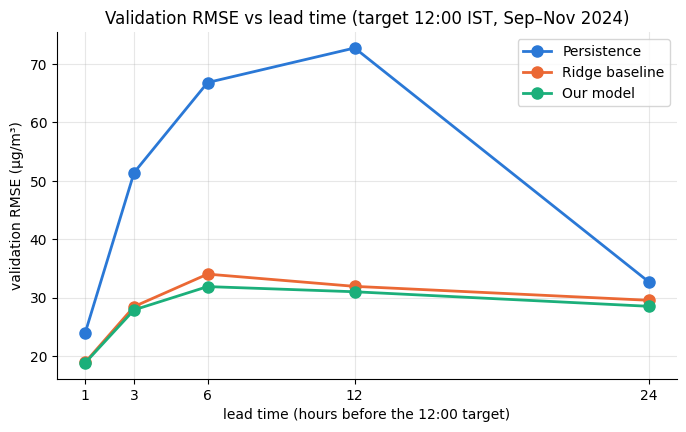

1-hour nowcast (reported separately):


,RMSE,MAE,bias
method,,,
Persistence,23.95,10.36,6.37
Ridge baseline,18.95,8.67,0.50
Our model,18.86,7.95,0.45


Day-ahead (24 h, the main task):


,RMSE,MAE,bias
method,,,
Persistence,32.75,17.47,-0.47
Ridge baseline,29.58,18.16,5.32
Our model,28.55,16.35,0.74


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name in ["Persistence", "Ridge baseline", "Our model"]:
    d = lead_df[lead_df.method == name]
    ax.plot(d.lead_h, d.RMSE, "o-", color=P.METHOD_COLORS[name], label=name, markersize=8)
ax.set_xticks(LEADS); ax.set_xlabel("lead time (hours before the 12:00 target)")
ax.set_ylabel("validation RMSE (µg/m³)"); ax.set_title("Validation RMSE vs lead time (target 12:00 IST, Sep–Nov 2024)")
ax.legend(); savefig(fig, "part3_rmse_vs_lead.png"); plt.show()

print("1-hour nowcast (reported separately):")
display(lead_df[lead_df.lead_h == 1].set_index("method")[["RMSE", "MAE", "bias"]].round(2))
print("Day-ahead (24 h, the main task):")
display(lead_df[lead_df.lead_h == 24].set_index("method")[["RMSE", "MAE", "bias"]].round(2))

### Why does persistence behave as it does? The daily cycle

Persistence at lead $L$ says "PM2.5 at 12:00 tomorrow = PM2.5 at $12{:}00 - L$". If PM2.5 has a strong daily cycle, then a reading taken at a *different hour of the day* is systematically different from a noon reading, even when nothing else changes. Only $L = 24$ h compares noon with noon.

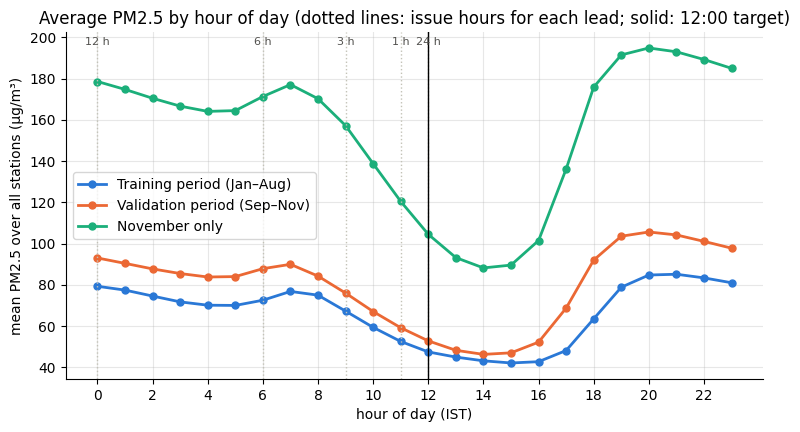

timestamp,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
Training period (Jan–Aug),79.3,77.5,74.6,71.7,70.1,70.0,72.6,76.8,75.0,67.3,59.4,52.6,47.5,45.0,43.2,42.1,42.8,48.2,63.5,78.8,84.8,85.1,83.4,81.0
Validation period (Sep–Nov),93.0,90.4,87.7,85.5,83.8,84.0,87.8,90.0,84.2,76.0,67.1,59.2,52.8,48.3,46.3,47.1,52.2,68.8,92.0,103.6,105.6,104.2,101.1,97.8
November only,178.5,174.7,170.4,166.6,164.1,164.5,171.3,177.1,170.2,157.2,138.7,120.4,104.5,93.2,88.2,89.6,101.5,136.2,175.9,191.4,194.8,193.0,189.2,184.9


persistence bias (forecast − observed) by lead:


,RMSE,bias
lead_h,,
1,23.95,6.37
3,51.43,23.17
6,66.82,35.00
12,72.74,40.19
24,32.75,-0.47


In [ ]:
hod = pd.DataFrame({
    "Training period (Jan–Aug)": W.loc[: C.TRAIN_TARGET_END].mean(axis=1).groupby(lambda t: t.hour).mean(),
    "Validation period (Sep–Nov)": W.loc["2024-09-01":].mean(axis=1).groupby(lambda t: t.hour).mean(),
    "November only": W.loc["2024-11-01":].mean(axis=1).groupby(lambda t: t.hour).mean(),
})
fig, ax = plt.subplots(figsize=(9, 4.5))
for col, c in zip(hod.columns, ["#2a78d6", "#eb6834", "#1baf7a"]):
    ax.plot(hod.index, hod[col], "o-", color=c, label=col, markersize=5)
for L in LEADS:
    hr = (12 - L) % 24
    ax.axvline(hr, color="#c3c2b7", lw=1, ls=":")
    ax.text(hr, ax.get_ylim()[1] * 0.97, f"{L} h", ha="center", fontsize=8, color="#52514e")
ax.axvline(12, color="black", lw=1)
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hour of day (IST)"); ax.set_ylabel("mean PM2.5 over all stations (µg/m³)")
ax.set_title("Average PM2.5 by hour of day (dotted lines: issue hours for each lead; solid: 12:00 target)")
ax.legend(); savefig(fig, "part3_hour_of_day.png"); plt.show()
display(hod.round(1).T)
print("persistence bias (forecast − observed) by lead:")
display(lead_df[lead_df.method == "Persistence"].set_index("lead_h")[["RMSE", "bias"]].round(2))

### Answers to the Part 3 questions

**Results.**
* **1-hour nowcast** (reported separately): our model 18.86 RMSE / 7.95 MAE, ridge 18.95, persistence 23.95.
* **Day-ahead (24 h):** our model 28.55, ridge 29.58, persistence 32.75.

**Persistence at 1 h, 24 h and in between.** Yes, there is a striking difference. Persistence RMSE is 24 at 1 h, then **jumps to 51 (3 h), 67 (6 h) and 73 (12 h)**, and **dips back to 33 at 24 h**. The reason is the **daily cycle**:
* Bihar PM2.5 rises steeply after sunset, peaks in the evening (validation mean ≈ 106 µg/m³ at 20:00), stays high through the night and morning (≈ 93 at 00:00, 88 at 06:00) and is lowest in the early afternoon (≈ 53 at 12:00, 46 at 14:00).
* The cause is the boundary layer: a shallow, stable layer at night traps emissions, and daytime heating mixes them through a deep layer.
* Persistence from 00:00 or 06:00 therefore copies a *night* level onto a *noon* target, a systematic over-forecast. Its bias is +40 µg/m³ at 12 h, +35 at 6 h and +23 at 3 h, and the bias grows with the pollution level (November nights ≈ 170–190 µg/m³ vs noon ≈ 105).
* At 24 h the forecast compares **noon with noon**, so the cycle cancels (bias −0.5). Hence the dip.
* At 1 h the cycle has had little time to act (11:00 vs 12:00), although noon is still lower than 11:00 (bias +6).

**Do the learned models show the same behaviour?** Mostly **no**:
* Refitted for each lead, they learn the average night-to-noon drop, so the huge persistence bias disappears (RMSE 31–34 at 6–12 h instead of 67–73).
* Their error grows roughly smoothly with lead, but they show a **mild version of the dip**: 6 h (31.9) and 12 h (31.0) are worse than 24 h (28.55), even though a 12 h forecast has strictly more information.
* **Why:** these models fit training slightly *better* at 6–12 h (train RMSE 22.5–23.4 vs 23.9 at 24 h), but in November they over-forecast by +9 to +15 µg/m³. From a night-time issue the model must predict a large *drop* whose size scales with the level. November's drops (≈ −70 µg/m³) are larger than most drops in training, and the trees cannot extrapolate them. At 24 h the expected change is near zero, so no such extrapolation is needed.

**Which lead time for a public warning service, and what does it cost?** **24 h** (issued at noon for the next noon): people need time to plan (school activities, outdoor work, masks, vulnerable groups). The cost compared with a 1-hour nowcast is about **+9.7 µg/m³ RMSE (28.55 vs 18.86)** and +8.4 MAE. An 11:00 "nowcast" is too late to act on. Interestingly, issuing at 00:00 or 06:00 on the day itself would *not* be more accurate than the 24 h forecast, for the daily-cycle reasons above.

---
# Part 4 : Forecast maps vs observed maps

## 4.1 Inverse-distance weighting (IDW)

**What:** turn the 468 station values into a value at each of the 3,396 grid points:
$$z(g) = \frac{\sum_j w_{gj} z_j}{\sum_j w_{gj}},\qquad w_{gj} = \frac{1}{d(g,j)^2},$$
using **all** stations and km distances. If a grid point coincides with a station ($d = 0$) it takes that station's value (no division by zero).
**Why the same weights for everything:** the weight matrix depends only on geometry, so we build it once. Observed, persistence and our forecast all go through the *same* linear map, any difference between maps comes only from the forecasts.


grid points: 3396 | grid points within 0.01 km of a station: 0


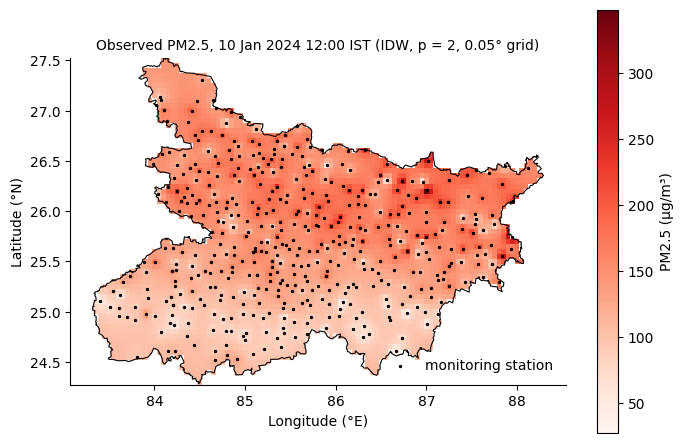

In [ ]:
grid = pd.read_csv(C.BIHAR_GRID)
boundary = pd.read_csv(C.BIHAR_BOUNDARY)
grid_xy = D.to_km(grid["longitude"], grid["latitude"])
Widw = IDW.idw_weight_matrix(grid_xy, xy, power=C.IDW_POWER)          # (3396, 468)
assert Widw.shape == (3396, 468) and np.allclose(Widw.sum(axis=1), 1)
print("grid points:", len(grid), "| grid points within 0.01 km of a station:", int((D.distance_matrix_km(grid_xy, xy).min(axis=1) < 0.01).sum()))

obs_day = y_va.reshape(91, S)                  # observed at each validation target (day x station)
ours_day = ours_va.reshape(91, S)
pers_day = pers_va.reshape(91, S)
obs_map, ours_map, pers_map = IDW.interpolate(Widw, obs_day), IDW.interpolate(Widw, ours_day), IDW.interpolate(Widw, pers_day)

# reproduce the PDF's Figure 1 (training day, observed only) as a check of the map style
fig, ax = plt.subplots(figsize=(8, 5.5))
m = P.draw_map(ax, grid, IDW.interpolate(Widw, W.loc["2024-01-10 12:00"].to_numpy()), boundary, stations,
               title="Observed PM2.5, 10 Jan 2024 12:00 IST (IDW, p = 2, 0.05° grid)")
fig.colorbar(m, ax=ax, label=P.PM_UNITS); ax.legend(loc="lower right", frameon=False)
savefig(fig, "part4_figure1_check.png"); plt.show()

## 4.2 Three validation days: clean, polluted, and our worst day

* **clean** = the target day with the lowest observed network mean,
* **polluted** = the highest observed network mean,
* **worst** = the day where our model's station RMSE is highest.

Each figure: observed | our forecast | persistence (one shared colour scale) | our forecast − observed (diverging scale centred on 0).

clean     15 Sep 2024: network mean    7.9 µg/m³, station RMSE ours   19.3, persistence   27.3
polluted  27 Nov 2024: network mean  175.0 µg/m³, station RMSE ours   64.4, persistence   71.7
worst     29 Nov 2024: network mean   76.6 µg/m³, station RMSE ours   90.5, persistence  112.0


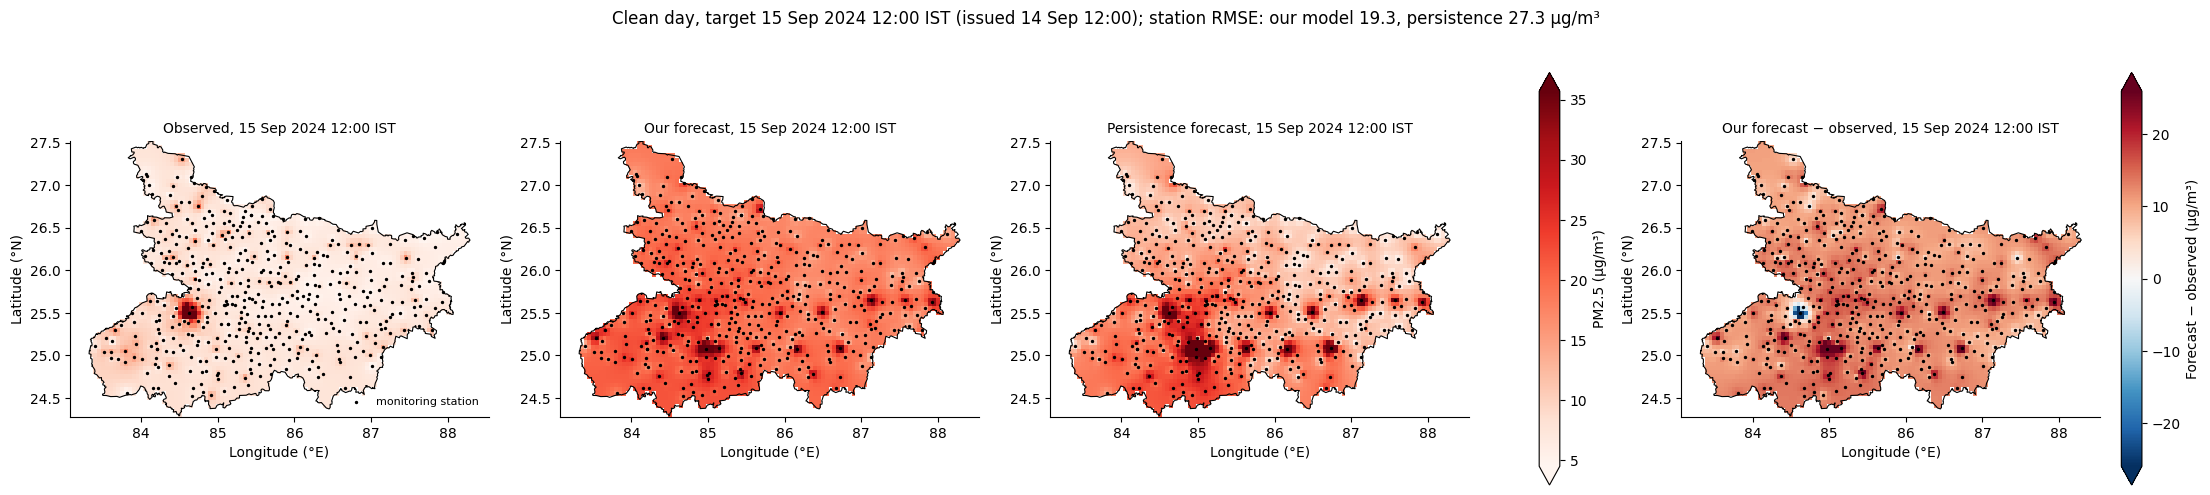

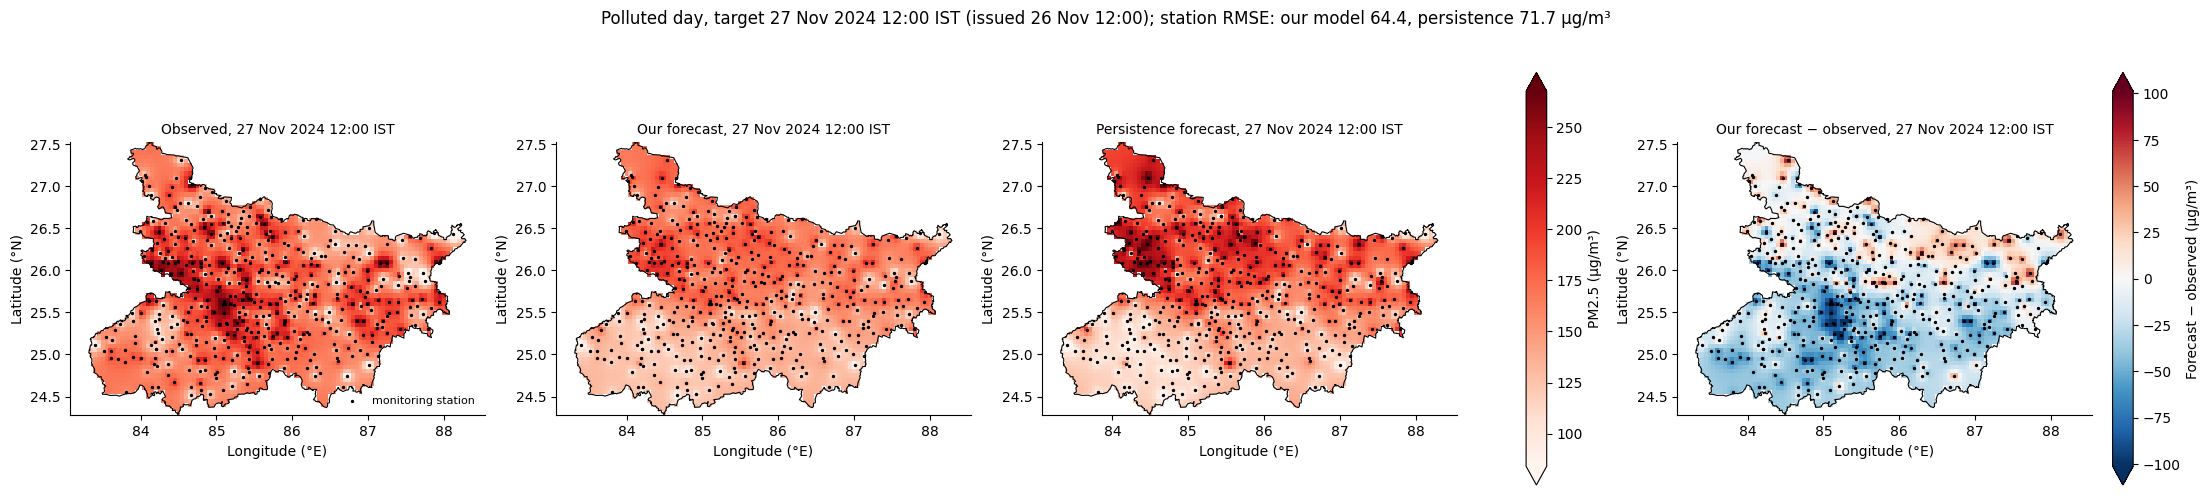

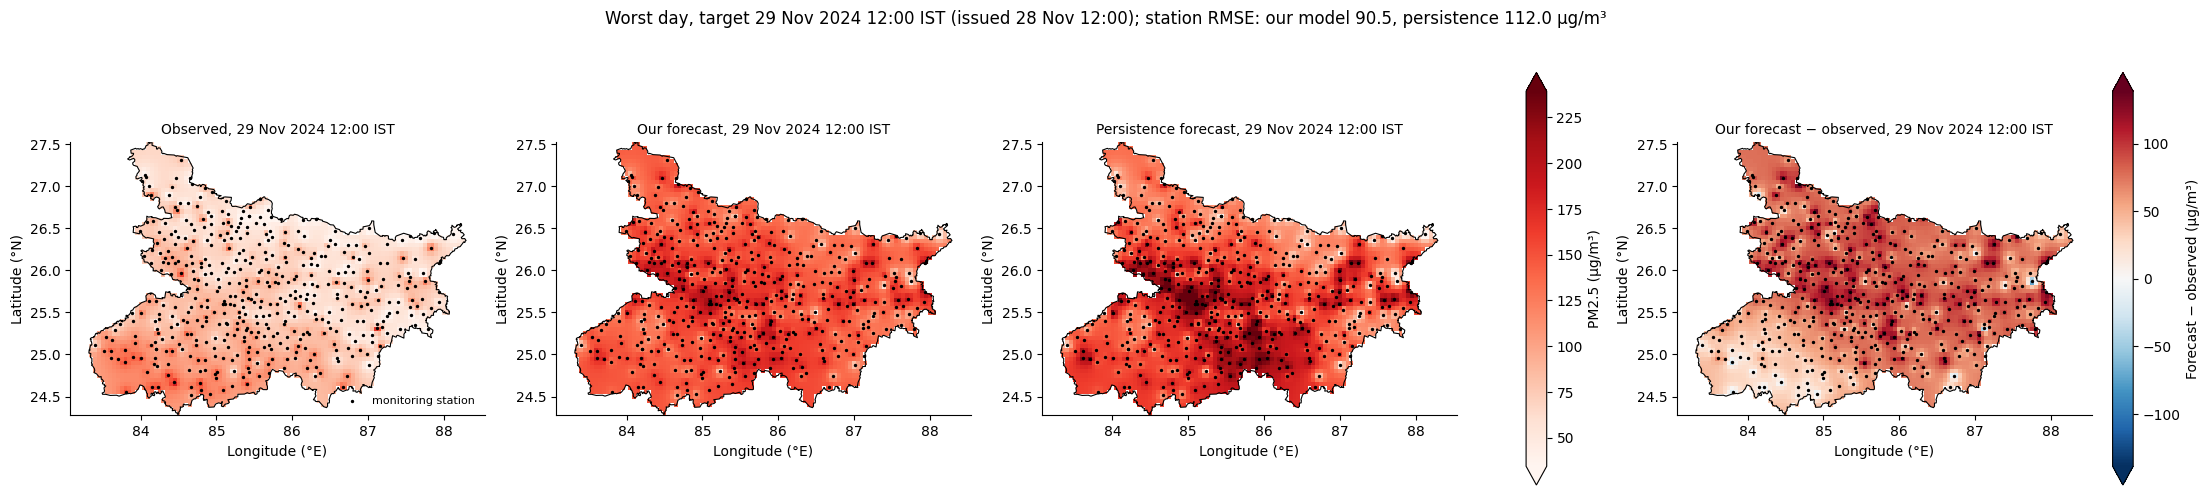

In [ ]:
day_obs_mean = obs_day.mean(axis=1)
day_rmse_ours = np.sqrt(((ours_day - obs_day) ** 2).mean(axis=1))
day_rmse_pers = np.sqrt(((pers_day - obs_day) ** 2).mean(axis=1))
i_clean, i_poll, i_worst = int(np.argmin(day_obs_mean)), int(np.argmax(day_obs_mean)), int(np.argmax(day_rmse_ours))
if i_worst == i_poll:                       # keep three different days
    i_poll = int(np.argsort(day_obs_mean)[-2])
picked = {"clean": i_clean, "polluted": i_poll, "worst": i_worst}
for kind, i in picked.items():
    print(f"{kind:9s} {va_tg[i]:%d %b %Y}: network mean {day_obs_mean[i]:6.1f} µg/m³, station RMSE ours {day_rmse_ours[i]:6.1f}, persistence {day_rmse_pers[i]:6.1f}")

for kind, i in picked.items():
    when = f"{va_tg[i]:%d %b %Y} 12:00 IST"
    fig = P.four_panel_figure(grid, boundary, stations, obs_map[i], ours_map[i], pers_map[i], when,
                              day_info=f"{kind.capitalize()} day, target {when} (issued {va_tg[i] - pd.Timedelta(hours=24):%d %b} 12:00); "
                                       f"station RMSE: our model {day_rmse_ours[i]:.1f}, persistence {day_rmse_pers[i]:.1f} µg/m³")
    savefig(fig, f"part4_maps_{kind}.png"); plt.show()

## 4.3 Map RMSE and pattern correlation for every validation day

* **map RMSE** of a day = $\sqrt{\text{mean over grid cells of } (\text{forecast map} - \text{observed map})^2}$,
* **pattern correlation** = Pearson correlation across the 3,396 grid cells between forecast map and observed map (does the forecast put the high and low areas in the right *places*, regardless of overall level?).

We report averages over the 91 days, next to station RMSE (both pooled over all rows and as a mean of daily values, to compare like with like).

,mean daily map RMSE,mean daily station RMSE,pooled station RMSE,mean pattern correlation,median pattern correlation
method,,,,,
Persistence,15.369,28.568,32.745,0.580,0.624
Our model,14.172,24.877,28.555,0.618,0.656


spatial std across stations (mean over days): observed 30.4 | across grid cells: observed map 14.0


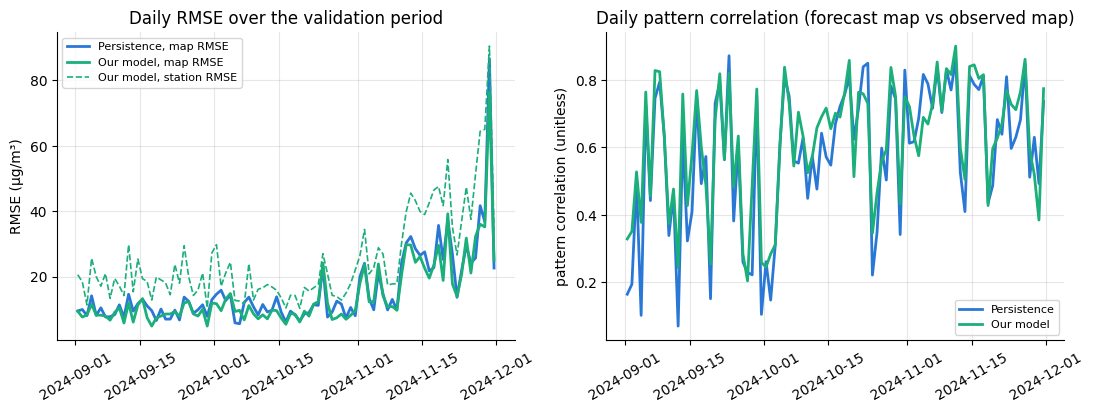

In [ ]:
def pattern_corr(A, B):
    A = A - A.mean(axis=1, keepdims=True); B = B - B.mean(axis=1, keepdims=True)
    return (A * B).sum(axis=1) / np.sqrt((A ** 2).sum(axis=1) * (B ** 2).sum(axis=1))

map_rows = []
for name, fmap, fday, pooled in [("Persistence", pers_map, pers_day, pers_va), ("Our model", ours_map, ours_day, ours_va)]:
    map_rmse_day = np.sqrt(((fmap - obs_map) ** 2).mean(axis=1))
    st_rmse_day = np.sqrt(((fday - obs_day) ** 2).mean(axis=1))
    pc = pattern_corr(fmap, obs_map)
    map_rows.append({"method": name, "mean daily map RMSE": map_rmse_day.mean(), "mean daily station RMSE": st_rmse_day.mean(),
                     "pooled station RMSE": M.rmse(pooled, y_va), "mean pattern correlation": pc.mean(),
                     "median pattern correlation": np.median(pc)})
    if name == "Our model": ours_daily = (map_rmse_day, st_rmse_day, pc)
    else: pers_daily = (map_rmse_day, st_rmse_day, pc)
map_table = pd.DataFrame(map_rows).set_index("method").round(3)
map_table.to_csv(RES_DIR / "part4_map_metrics.csv")
display(map_table)

# how smooth are the maps compared with the stations?
print("spatial std across stations (mean over days): observed %.1f" % obs_day.std(axis=1).mean(),
      "| across grid cells: observed map %.1f" % obs_map.std(axis=1).mean())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(va_tg, pers_daily[0], color=P.METHOD_COLORS["Persistence"], label="Persistence, map RMSE")
axes[0].plot(va_tg, ours_daily[0], color=P.METHOD_COLORS["Our model"], label="Our model, map RMSE")
axes[0].plot(va_tg, ours_daily[1], color=P.METHOD_COLORS["Our model"], ls="--", lw=1.2, label="Our model, station RMSE")
axes[0].set_ylabel("RMSE (µg/m³)"); axes[0].set_title("Daily RMSE over the validation period"); axes[0].legend(fontsize=8)
axes[1].plot(va_tg, pers_daily[2], color=P.METHOD_COLORS["Persistence"], label="Persistence")
axes[1].plot(va_tg, ours_daily[2], color=P.METHOD_COLORS["Our model"], label="Our model")
axes[1].set_ylabel("pattern correlation (unitless)"); axes[1].set_title("Daily pattern correlation (forecast map vs observed map)"); axes[1].legend(fontsize=8)
for ax in axes: ax.tick_params(axis="x", rotation=30)
savefig(fig, "part4_daily_map_metrics.png"); plt.show()

### Answers to the Part 4 questions

**The three days.**
* **Clean, 15 Sep:** network mean 7.9 µg/m³. Our model 19.3 vs persistence 27.3 station RMSE.
* **Polluted, 27 Nov:** 175 µg/m³. Our model 64.4 vs persistence 71.7.
* **Our worst day, 29 Nov:** 90.5 vs 112.0. The network mean collapsed from ≈ 159 to 77 µg/m³ in one day (a weather change). Both forecasts are far too high everywhere; the difference panel is red over the whole state.

**Which RMSE is better, map or station?** Map RMSE is much lower: for our model 14.2 vs 24.9 µg/m³ (means of daily values; persistence 15.4 vs 28.6). IDW averages many stations, so both maps are smooth: the spatial standard deviation is 30.4 across stations but only 14.0 across grid cells. Station-level noise and local extremes are averaged away *in both maps*, so their difference shrinks. **The station RMSE should be quoted as forecast accuracy**: it compares forecasts with actual measurements, while map RMSE compares two interpolations and flatters every method.

**In what sense is the observed map not ground truth?** It is a model, not a measurement:
* away from stations it is a weighted average of distant sensors;
* it cannot show hotspots between stations, and it never exceeds the highest or falls below the lowest station value;
* with power 2 it creates "bull's-eyes" around individual stations;
* it inherits every sensor error and the unmarked upstream gap-filling;
* the boundary areas (few stations) are pure extrapolation.

**Pattern correlation vs RMSE.** Our model improves both: mean pattern correlation 0.618 vs 0.580, and map RMSE 14.2 vs 15.4.
* A forecast can have **excellent pattern correlation and poor RMSE**: take the 29 Nov forecast, which puts the more and less polluted areas roughly in the right places but is far too high everywhere (station RMSE 90 µg/m³). A uniform offset or a wrong amplitude leaves the correlation unchanged but inflates RMSE.
* **For a public warning, RMSE/bias matters more.** Warnings are issued when PM2.5 crosses a health threshold, so the *level* must be right. A perfectly shaped map at the wrong level triggers false alarms or misses real ones.

---
# Part 5 : Refit on all data up to 30 Nov and build the submission

**What:**
1. Refit the *same* model (same feature groups, same hyperparameters) on **all 12:00 targets up to 30 Nov** (issue days 8 Jan … 29 Nov). The fitted context (station long-run mean/std) is recomputed on readings up to 30 Nov 12:00, the "training rows" of this final fit.
2. Save everything `forecast()` needs in `submission/model.pkl` (only sklearn objects, numpy arrays and dicts, so it unpickles without our `src` package).
3. Copy `src/features.py` to `submission/features.py` **byte-for-byte**, plus `bihar_stations.csv`.
4. Prove that `forecast()` reproduces the notebook's predictions for the same model, then run the course's `check_submission.py`.

No hyperparameter is changed here: the December test is never used for any choice.

In [ ]:
all_targets = D.noon_targets(C.TRAIN_TARGET_START, C.VAL_TARGET_END)               # 12:00 targets up to 30 Nov
fin_pos, fin_tg = D.split_issue_positions(times, all_targets, lead=24, min_history=F.HISTORY_HOURS)
assert fin_tg.max() == C.VAL_TARGET_END
fin_end_pos = times.get_loc(C.VAL_TARGET_END)
ctx_final = F.make_context(xy, nbr_idx, V[: fin_end_pos + 1])                       # readings <= 30 Nov 12:00
Xf, fnames, _ = F.rich_features(V, times, fin_pos, ctx_final, groups=FM.FINAL_GROUPS)
yf = F.targets(V, fin_pos)
final_refit = FM.fit_final_models(Xf, yf, Xf[:, 0], BEST_ALPHA, BEST_ET)
print(f"final refit on {len(fin_pos)} issue days x {S} stations = {len(yf):,} rows ({times[fin_pos[0]]:%d %b} ... {times[fin_pos[-1]]:%d %b} issue)")

bundle = {"models": final_refit, "ctx": ctx_final, "groups": list(FM.FINAL_GROUPS), "lead": 24,
          "station_ids": [str(s) for s in STATION_IDS], "feature_names": fnames,
          "description": f"avg(Scaler+Ridge a={BEST_ALPHA:g}, ExtraTrees {BEST_ET}) on change from persistence; refit on 12:00 targets to 30 Nov 2024"}
C.SUBMISSION_DIR.mkdir(exist_ok=True)
joblib.dump(bundle, C.SUBMISSION_DIR / "model.pkl", compress=3)
shutil.copyfile(MP1 / "src" / "features.py", C.SUBMISSION_DIR / "features.py")
shutil.copyfile(C.BIHAR_STATIONS, C.SUBMISSION_DIR / "bihar_stations.csv")

sha = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
assert sha(MP1 / "src" / "features.py") == sha(C.SUBMISSION_DIR / "features.py"), "feature code must be identical"
print("submission/features.py is similar to src/features.py:", sha(C.SUBMISSION_DIR / "features.py")[:16], "...")
print("model.pkl size: %.1f MB" % ((C.SUBMISSION_DIR / "model.pkl").stat().st_size / 1e6))

final refit on 327 issue days x 468 stations = 153,036 rows (08 Jan ... 29 Nov issue)
submission/features.py is byte-identical to src/features.py: 899fcacbb41fcfe7 ...
model.pkl size: 11.7 MB


### Does `forecast.py` give exactly the notebook's predictions?

We import `submission/forecast.py` as the grader does, call it for the 30 November issue times that `check_submission.py` uses, and compare with predictions the notebook computes for the same refitted model from the full data matrix. (These November numbers are *in-sample* for the refitted model, so they are a consistency check, not a score.)

In [ ]:
spec = importlib.util.spec_from_file_location("forecast_submission", C.SUBMISSION_DIR / "forecast.py")
sys.path.insert(0, str(C.SUBMISSION_DIR))
fc = importlib.util.module_from_spec(spec); spec.loader.exec_module(fc)
sys.path.remove(str(C.SUBMISSION_DIR))

nov_issue = pd.date_range("2024-10-31 12:00", "2024-11-29 12:00", freq="D")
nov_pos = F.positions_of(times, nov_issue)
Xn, _, _ = F.rich_features(V, times, nov_pos, ctx_final, groups=FM.FINAL_GROUPS)
nb_pred = FM.predict_final(final_refit, Xn, Xn[:, 0]).reshape(len(nov_issue), S)

max_diff, call_times = 0.0, []
for k, t in enumerate(nov_issue):
    t0 = time.perf_counter()
    out = fc.forecast(W.loc[:t].copy(), t)
    call_times.append(time.perf_counter() - t0)
    assert isinstance(out, pd.Series) and list(out.index) == list(STATION_IDS) and np.isfinite(out).all() and (out >= 0).all()
    max_diff = max(max_diff, float(np.max(np.abs(out.to_numpy() - nb_pred[k]))))
print(f"max |forecast.py - notebook| over 30 days x 468 stations: {max_diff:.2e} µg/m³")
print(f"forecast() call time: median {np.median(call_times):.3f} s, max {np.max(call_times):.3f} s")
assert max_diff < 1e-6

max |forecast.py - notebook| over 30 days x 468 stations: 1.22e-12 µg/m³
forecast() call time: median 0.058 s, max 0.161 s


In [ ]:
r = subprocess.run([sys.executable, str(C.PACKAGE_DIR / "starter" / "check_submission.py"), str(C.SUBMISSION_DIR)],
                   capture_output=True, text=True, cwd=str(MP1), timeout=900)
print(r.stdout); print(r.stderr[-2000:])
assert "OK - format and timing look right" in r.stdout
_ = (RES_DIR / "check_submission_output.txt").write_text(r.stdout)

Running /content/submission/forecast.py on 30 November issue times ...

Call time: median 0.06 s, max 0.07 s

November sanity check over 30 forecasts (NOT a test score):
  your forecast  RMSE  38.61  MAE  26.23
  persistence    RMSE  47.81  MAE  31.70

RESULT: OK - format and timing look right.




**Interpretation.**
* **The refit:** 327 issue days × 468 = 153,036 rows (8 Jan … 29 Nov issues), with the same groups and hyperparameters as chosen on validation.
* **Train/serve consistency:** `forecast.py` uses a byte-identical `features.py` and reproduces the notebook's predictions to 1e-12 µg/m³. Each call takes ≈ 0.06 s (limit 10 s).
* **The checker:** `check_submission.py` reports **OK**. Its November RMSE (38.6 vs persistence 47.8) is **in-sample** for this refitted model (November targets are now training data), so it is only a sanity check, not a score. The honest estimate of December performance is our validation result (RMSE ≈ 28.6), with the caveat that December is the peak smog season, where errors are typically larger (compare November).

In [ ]:
print(f"notebook finished in {(time.time() - T0) / 60:.1f} min")

notebook finished in 56.8 min
